# Rede de Visibilidade a partir de Dados do INMET — Fortaleza (A304)

**Trabalho computacional — Análise de Redes Complexas**

Estação A304 (Fortaleza-CE), utilizando a série de **temperatura máxima diária** como série temporal de entrada de redes de visibilidade.

**Parte I — Preparação dos dados e criação da rede**
1. Coleta, padronização e agregação dos dados horários do INMET.
2. Diagnóstico de completude da série.
3. Detecção dos eventos CTX90pct e EHF.
4. Recorte principal para 2008–2021 e tratamento da falha curta de dezembro de 2014.
5. Construção do HVG e do NVG com `ts2vg`.
6. Acoplamento dos metadados climáticos aos nós.
7. Tratamento dos empates (desempate com semente fixa) e validação do HVG contra modelos nulos (i.i.d. de Luque et al. (2009), embaralhamento e surrogates de fase).

**Parte II — Análise estrutural da rede**
1. Tamanho, densidade e componentes conexos.
2. Distribuição de graus.
3. Transitividade e agrupamento local.
4. Distâncias geodésicas.
5. Cruzamento dos Top 15 hubs do HVG com as ondas de calor.
6. Comparação com redes de referência (small-world) e robustez do cruzamento hubs × ondas.

**Parte III - Centralidade dos vértices**
1. Centralidades geométricas: excentricidade, proximidade, harmônica.
2. Centralidade de intermediação.
3. PageRank.
4. K-núcleos.
5. Agrupamento local.
6. Assortatividade de grau.

--- Métricas ---

7. Restrição de Burt
8. Centralidade de subgrafo de estrada

As análises de visibilidade são apresentadas para **HVG** (*Horizontal Visibility Graph*) e **NVG** (*Natural Visibility Graph*), com HVG como rede principal no cruzamento com os eventos.

## 1 · Imports, diretórios e padrão visual

In [ ]:
import io
import sys
import time
import warnings
import zipfile
from collections import Counter
from importlib.metadata import version
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pymannkendall as mk
import requests
from scipy import stats as sp_stats
from scipy.sparse.csgraph import shortest_path
from scipy.stats import rankdata, spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm
from ts2vg import HorizontalVG, NaturalVG

warnings.filterwarnings("ignore")

RAW_DIR = Path("data/raw")
PROCESSED_DIR = Path("data/processed")
PLOTS_DIR = Path("data/plots")

for diretorio in (RAW_DIR, PROCESSED_DIR, PLOTS_DIR):
    diretorio.mkdir(parents=True, exist_ok=True)

STATION_CODE = "A304"
ANOS = list(range(2003, 2024))
BASE_URL = "https://portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip"

COR_HVG        = "#6A3D9A"
COR_HVG_CLARO  = "#B9A0D6"
COR_NVG        = "#009E73"
COR_NVG_CLARO  = "#80CEB9"
COR_CALOR      = "#E69F00"
COR_TEMP       = "#8C9BB0"
COR_SERIE      = "#00468A"
COR_TEORICO    = "#1A1A1A"
COR_NULO       = "#8C8C8C"
COR_PICO       = "#4D4D4D"
COR_ARESTA     = "#B5B9BF"
COR_GRID       = "#EBEAEB"

FUNDO = CARTA = "#ffffff"
BORDA = "#333333"
TEXTO = "#000000"

CORES_REDE       = {"HVG": COR_HVG, "NVG": COR_NVG}
CORES_REDE_CLARO = {"HVG": COR_HVG_CLARO, "NVG": COR_NVG_CLARO}
MARCADOR_REDE    = {"HVG": "o", "NVG": "s"}

plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": CARTA, "savefig.facecolor": FUNDO,
    "axes.edgecolor": BORDA, "axes.labelcolor": TEXTO, "text.color": TEXTO,
    "xtick.color": TEXTO, "ytick.color": TEXTO,
    "grid.color": COR_GRID, "grid.linewidth": 0.5,
    "legend.facecolor": CARTA, "legend.edgecolor": COR_GRID, "legend.labelcolor": TEXTO,
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.6, "lines.markersize": 5,
    "savefig.bbox": "tight", "svg.fonttype": "none",
})

def estilizar_ax(ax):
    ax.set_facecolor(CARTA)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_edgecolor(BORDA)
    ax.tick_params(colors=TEXTO, labelsize=8)
    ax.grid(True, color=COR_GRID, linewidth=0.5, alpha=0.8)
    ax.set_axisbelow(True)

def rotular_painel(ax, letra):
    """Letra do painel (a, b, c...) em negrito no canto superior esquerdo."""
    ax.text(-0.12, 1.06, letra, transform=ax.transAxes, fontsize=11, fontweight="bold", va="bottom")

def salvar_mostrar(fig, nome_arquivo):
    fig.savefig(PLOTS_DIR / nome_arquivo, dpi=300)
    plt.show()
    plt.close(fig)
# ==========================================================================

SEED_DESEMPATE = 42      # semente do ruído que desempata valores iguais
SIGMA_DESEMPATE = 1e-6   # °C; muito menor que a resolução do sensor (0,1 °C)
SEED_NULOS = 7
N_REP_NULOS = 200

print("Versões:", {
    "python": sys.version.split()[0],
    **{p: version(p) for p in ("numpy", "pandas", "networkx", "scipy", "ts2vg")},
})

Versões: {'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'networkx': '3.7', 'scipy': '1.16.3', 'ts2vg': '1.2.4'}


## 2 · Dados do INMET
Padronizando as colunas e valores inválidos convertidos para 'NaN'.

Salvando as observações horárias agregadas em escala diária


In [ ]:
_horario_path = PROCESSED_DIR / "fortaleza_horario.parquet"
_diario_path  = PROCESSED_DIR / "fortaleza_diario.parquet"

def download_ano(ano: int) -> pd.DataFrame | None:
    url = BASE_URL.format(ano=ano)
    destino_csv = RAW_DIR / f"inmet_{STATION_CODE}_{ano}.csv"

    if destino_csv.exists():
        try:
            return pd.read_csv(
                destino_csv,
                sep=";",
                encoding="utf-8",
                skiprows=8
            )
        except Exception:
            return pd.read_csv(
                destino_csv,
                sep=";",
                encoding="latin-1",
                skiprows=8
            )

    try:
        resposta = requests.get(url, timeout=120)
        resposta.raise_for_status()
    except requests.exceptions.RequestException as erro:
        print(f"  [{ano}] ERRO no download: {erro}")
        return None

    with zipfile.ZipFile(io.BytesIO(resposta.content)) as arquivo_zip:
        arquivos_estacao = [
            nome for nome in arquivo_zip.namelist()
            if STATION_CODE in nome.upper()
        ]

        if not arquivos_estacao:
            print(f"  [{ano}] Estação {STATION_CODE} não encontrada.")
            return None

        with arquivo_zip.open(arquivos_estacao[0]) as arquivo:
            conteudo = arquivo.read().decode("latin-1")

        destino_csv.write_text(conteudo, encoding="utf-8")

        return pd.read_csv(
            io.StringIO(conteudo),
            sep=";",
            skiprows=8,
            encoding="utf-8"
        )


def padronizar_colunas(df: pd.DataFrame) -> pd.DataFrame:
    mapeamento = {}

    for coluna in df.columns:
        c = coluna.upper().strip()

        if c.startswith("DATA"):
            mapeamento[coluna] = "data"
        elif c.startswith("HORA"):
            mapeamento[coluna] = "hora_utc"
        elif "TEMPERATURA" in c and "ORVALHO" not in c:
            if "XIMA" in c:
                mapeamento[coluna] = "temp_max"
            elif "NIMA" in c:
                mapeamento[coluna] = "temp_min"
            else:
                mapeamento[coluna] = "temp_ar"
        elif "UMIDADE RELATIVA" in c and ("HORARIA" in c or "HORÁRIA" in c):
            mapeamento[coluna] = "umidade"
        elif "PRECIPITA" in c:
            mapeamento[coluna] = "precipitacao"
        elif "PRESS" in c and "ESTA" in c:
            mapeamento[coluna] = "pressao"
        elif "VENTO" in c and "VELOCIDADE" in c:
            mapeamento[coluna] = "vento_vel"
        elif "VENTO" in c and "DIRE" in c:
            mapeamento[coluna] = "vento_dir"
        elif "RADIA" in c and "GLOBAL" in c:
            mapeamento[coluna] = "radiacao"

    df = df.rename(columns=mapeamento)
    df = df.loc[:, ~df.columns.duplicated()]

    colunas_alvo = [
        "data", "hora_utc", "temp_ar", "temp_max", "temp_min",
        "umidade", "precipitacao", "pressao", "vento_vel",
        "vento_dir", "radiacao"
    ]

    return df[[c for c in colunas_alvo if c in df.columns]].copy()


def tratar_valores(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    df.replace(
        {9999: np.nan, -9999: np.nan, "9999": np.nan, "-9999": np.nan},
        inplace=True
    )

    numericas = [
        "temp_ar", "temp_max", "temp_min", "umidade",
        "precipitacao", "pressao", "vento_vel",
        "vento_dir", "radiacao"
    ]

    for coluna in numericas:
        if coluna in df.columns:
            df[coluna] = (
                df[coluna]
                .astype(str)
                .str.replace(",", ".", regex=False)
                .replace("nan", np.nan)
            )
            df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

    if "data" in df.columns and "hora_utc" in df.columns:
        datas_limpas = pd.to_datetime(
            df["data"].astype(str),
            errors="coerce"
        )

        horas_limpas = (
            df["hora_utc"]
            .astype(str)
            .str.replace(":", "", regex=False)
            .str.zfill(4)
            .str[:2]
        )

        horas_delta = pd.to_timedelta(
            pd.to_numeric(horas_limpas, errors="coerce"),
            unit="h"
        )

        df["datetime_utc"] = datas_limpas + horas_delta
        df["datetime_brt"] = df["datetime_utc"] - pd.Timedelta(hours=3)

        df.drop(
            columns=["data", "hora_utc", "datetime_utc"],
            inplace=True
        )

    return df


def coletar_serie_historica(anos: list[int]) -> pd.DataFrame:
    frames = []

    for ano in tqdm(anos, desc="Processando"):
        df_ano = download_ano(ano)

        if df_ano is None:
            continue

        df_ano = padronizar_colunas(df_ano)
        df_ano = tratar_valores(df_ano)

        n = (
            df_ano["temp_ar"].notna().sum()
            if "temp_ar" in df_ano.columns
            else len(df_ano)
        )

        print(f"  → Ano {ano}: {n} leituras de temperatura resgatadas.")
        frames.append(df_ano)

    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


def agregar_diario(df_horario: pd.DataFrame) -> pd.DataFrame:
    df = df_horario.copy()
    df["data"] = df["datetime_brt"].dt.normalize()

    return (
        df.groupby("data")
        .agg(
            temp_max=("temp_ar", "max"),
            temp_min=("temp_ar", "min"),
            temp_media=("temp_ar", "mean"),
            umidade_med=("umidade", "mean"),
            pressao_med=("pressao", "mean"),
            vento_med=("vento_vel", "mean"),
            prec_total=("precipitacao", "sum"),
        )
        .reset_index()
    )

# ==========================================================================
if _horario_path.exists() and _diario_path.exists():
    print("Dados processados já existem localmente em data/processed/ -- PULA DOWNLOAD E TRATAMENTO INTEGRAL.")
    serie_horaria = pd.read_parquet(_horario_path)
    serie_diaria  = pd.read_parquet(_diario_path)
    print(f"✓ Dados horários carregados com sucesso: {len(serie_horaria):,} registros.")
    print(f"✓ Dados diários carregados com sucesso : {len(serie_diaria):,} dias.")
else:
    print(f"\n{'='*60}")
    print(f"  PROCESSAMENTO INMET — ESTAÇÃO {STATION_CODE} (FORTALEZA-CE)")
    print(f"  Anos: {ANOS[0]}–{ANOS[-1]}")
    print(f"{'='*60}\n")

    serie_horaria = coletar_serie_historica(ANOS)
    serie_diaria = agregar_diario(serie_horaria)

    serie_horaria.to_parquet(_horario_path, engine="fastparquet", index=False)
    serie_diaria.to_parquet(_diario_path, engine="fastparquet", index=False)

    print(f"\n✓ Dados horários: {len(serie_horaria):,} registros salvos.")
    print(f"✓ Dados diários : {len(serie_diaria):,} dias salvos com sucesso.")
    if not serie_diaria.empty:
        print(
            f"✓ Período       : "
            f"{serie_diaria['data'].min()} → {serie_diaria['data'].max()}"
        )
# ==========================================================================


  PROCESSAMENTO INMET — ESTAÇÃO A304 (FORTALEZA-CE)
  Anos: 2003–2023



  → Ano 2003: 5008 leituras de temperatura resgatadas.


  → Ano 2004: 6771 leituras de temperatura resgatadas.


  → Ano 2005: 4923 leituras de temperatura resgatadas.


  → Ano 2006: 6442 leituras de temperatura resgatadas.


...

  → Ano 2020: 8147 leituras de temperatura resgatadas.


  → Ano 2021: 4110 leituras de temperatura resgatadas.


  → Ano 2022: 6085 leituras de temperatura resgatadas.


  → Ano 2023: 6133 leituras de temperatura resgatadas.



✓ Dados horários: 182,784 registros salvos.
✓ Dados diários : 7,617 dias salvos com sucesso.
✓ Período       : 2003-02-23 00:00:00 → 2023-12-31 00:00:00


## 3 · Diagnóstico de completude e falhas

Reindexando um calendário diário completo para localizar dias ausentes e blocos de falhas.

In [ ]:
diario_vg = pd.read_parquet(PROCESSED_DIR / "fortaleza_diario.parquet")
diario_vg["data"] = pd.to_datetime(diario_vg["data"])
diario_vg = diario_vg.sort_values("data").reset_index(drop=True)

calendario_completo = pd.date_range(
    diario_vg["data"].min(),
    diario_vg["data"].max(),
    freq="D"
)

diario_vg = (
    diario_vg
    .set_index("data")
    .reindex(calendario_completo)
    .rename_axis("data")
    .reset_index()
)

print(f"\n{'='*60}")
print("  DIAGNÓSTICO DE COMPLETUDE — TEMP_MAX")
print(f"{'='*60}\n")
print(
    f"Período: {calendario_completo.min().date()} "
    f"→ {calendario_completo.max().date()}"
)
print(f"Dias no calendário: {len(calendario_completo)}")
print(
    f"Dias com temp_max válido: "
    f"{diario_vg['temp_max'].notna().sum()} "
    f"({diario_vg['temp_max'].notna().mean()*100:.2f}%)"
)
print(
    f"Dias com temp_max faltante: "
    f"{diario_vg['temp_max'].isna().sum()} "
    f"({diario_vg['temp_max'].isna().mean()*100:.2f}%)"
)

resumo_ano = (
    diario_vg.assign(ano=diario_vg["data"].dt.year)
    .groupby("ano")["temp_max"]
    .apply(lambda s: s.notna().mean() * 100)
    .round(1)
)

print("\nCompletude de temp_max por ano:")
for ano, percentual in resumo_ano.items():
    marcador = "  <-- atenção" if percentual < 90 else ""
    print(f"  {ano}: {percentual:5.1f}%{marcador}")

falha = diario_vg["temp_max"].isna()
grupo_falha = (falha != falha.shift()).cumsum()

gaps = (
    diario_vg[falha]
    .assign(grupo=grupo_falha[falha])
    .groupby("grupo")
    .agg(
        inicio=("data", "min"),
        fim=("data", "max"),
        tamanho=("data", "size")
    )
    .sort_values("tamanho", ascending=False)
    .reset_index(drop=True)
)

print(f"\nTotal de blocos de falha (gaps): {len(gaps)}")

if not gaps.empty:
    print("\nDistribuição do tamanho dos gaps:")
    print(f"  1 dia    : {(gaps['tamanho'] == 1).sum()}")
    print(
        f"  2–3 dias : "
        f"{((gaps['tamanho'] >= 2) & (gaps['tamanho'] <= 3)).sum()}"
    )
    print(
        f"  4–7 dias : "
        f"{((gaps['tamanho'] >= 4) & (gaps['tamanho'] <= 7)).sum()}"
    )
    print(f"  >7 dias  : {(gaps['tamanho'] > 7).sum()}")

    print("\nOs 10 maiores gaps:")
    print(gaps.head(10).to_string(index=False))

gaps.to_csv(
    PROCESSED_DIR / "diagnostico_gaps_temp_max.csv",
    index=False
)


  DIAGNÓSTICO DE COMPLETUDE — TEMP_MAX

Período: 2003-02-23 → 2023-12-31
Dias no calendário: 7617
Dias com temp_max válido: 7021 (92.18%)
Dias com temp_max faltante: 596 (7.82%)

Completude de temp_max por ano:
  2003:  77.2%  <-- atenção
  2004:  78.4%  <-- atenção
  2005:  57.8%  <-- atenção
  2006:  77.5%  <-- atenção
  2007:  81.4%  <-- atenção
  2008: 100.0%
  2009: 100.0%
  2010: 100.0%
  2011: 100.0%
  2012: 100.0%
  2013: 100.0%
  2014:  96.4%
  2015: 100.0%
  2016: 100.0%
  2017: 100.0%
  2018: 100.0%
  2019: 100.0%
  2020: 100.0%
  2021: 100.0%
  2022:  89.6%  <-- atenção
  2023:  75.1%  <-- atenção

Total de blocos de falha (gaps): 20

Distribuição do tamanho dos gaps:
  1 dia    : 6
  2–3 dias : 1
  4–7 dias : 2
  >7 dias  : 11

Os 10 maiores gaps:
    inicio        fim  tamanho
2004-11-27 2005-04-25      150
2005-11-23 2006-03-18      116
2007-03-18 2007-05-24       68
2023-10-27 2023-12-31       66
2003-12-06 2004-01-30       56
2003-07-15 2003-08-28       45
2022-11-21 

## 4 · Detecção de ondas de calor

- **CTX90pct**
- **EHF (Excess Heat Factor)**

In [ ]:
def calcular_percentis_diarios(
    df,
    coluna,
    percentil=90,
    janela_dias=15,
    ano_ref_ini=2003,
    ano_ref_fim=2017
):
    df_ref = df[
        (df["data"].dt.year >= ano_ref_ini) &
        (df["data"].dt.year <= ano_ref_fim)
    ].copy()

    df_ref["dia_do_ano"] = df_ref["data"].dt.dayofyear

    janelas = {
        dia: {
            ((d - 1) % 366) + 1
            for d in range(
                dia - janela_dias,
                dia + janela_dias + 1
            )
        }
        for dia in range(1, 367)
    }

    resultado = {}

    for dia, dias_janela in janelas.items():
        mascara = df_ref["dia_do_ano"].isin(dias_janela)
        valores = df_ref.loc[mascara, coluna].dropna()

        resultado[dia] = (
            np.percentile(valores, percentil)
            if len(valores) > 0
            else np.nan
        )

    return pd.Series(
        resultado,
        name=f"p{int(percentil)}_{coluna}"
    )


def detectar_ctx90pct(df, percentis, min_dias=3):
    df = df.copy().sort_values("data").reset_index(drop=True)

    df["dia_do_ano"] = df["data"].dt.dayofyear
    df["p90_tmax"] = df["dia_do_ano"].map(percentis)
    df["excede_p90"] = df["temp_max"] > df["p90_tmax"]

    df["grupo"] = (
        df["excede_p90"] != df["excede_p90"].shift()
    ).cumsum()

    grupos_validos = (
        df[df["excede_p90"]]
        .groupby("grupo")
        .filter(lambda g: len(g) >= min_dias)["grupo"]
        .unique()
    )

    df["onda_ctx90"] = (
        df["grupo"].isin(grupos_validos) &
        df["excede_p90"]
    )

    mapeamento_ids = {
        grupo: i + 1
        for i, grupo in enumerate(grupos_validos)
    }

    df["id_evento_ctx90"] = (
        df["grupo"]
        .map(mapeamento_ids)
        .fillna(0)
        .astype(int)
    )

    df.loc[~df["onda_ctx90"], "id_evento_ctx90"] = 0

    return df.drop(columns=["grupo"])


def calcular_ehf(df, p95_serie):
    df = df.copy().sort_values("data").reset_index(drop=True)

    temperatura_media = df["temp_media"]

    T3 = temperatura_media.rolling(
        window=3,
        min_periods=1
    ).mean()

    T30 = (
        temperatura_media
        .shift(3)
        .rolling(window=30, min_periods=1)
        .mean()
    )

    df["EHIsig"] = T3 - p95_serie
    df["EHIaccl"] = T3 - T30
    df["EHF"] = (
        df["EHIsig"] *
        np.maximum(1, df["EHIaccl"])
    )

    df.loc[df["EHIsig"] <= 0, "EHF"] = 0.0

    return df


def detectar_ehf(df, min_dias=3):
    df = df.copy()

    df["positivo_ehf"] = (
        (df["EHIsig"] > 0) &
        (df["EHF"] > 0)
    )

    df["grupo_ehf"] = (
        df["positivo_ehf"] !=
        df["positivo_ehf"].shift()
    ).cumsum()

    grupos_validos = (
        df[df["positivo_ehf"]]
        .groupby("grupo_ehf")
        .filter(lambda g: len(g) >= min_dias)["grupo_ehf"]
        .unique()
    )

    df["onda_ehf"] = (
        df["grupo_ehf"].isin(grupos_validos) &
        df["positivo_ehf"]
    )

    mapeamento_ids = {
        grupo: i + 1
        for i, grupo in enumerate(grupos_validos)
    }

    df["id_evento_ehf"] = (
        df["grupo_ehf"]
        .map(mapeamento_ids)
        .fillna(0)
        .astype(int)
    )

    df.loc[~df["onda_ehf"], "id_evento_ehf"] = 0

    return df.drop(columns=["grupo_ehf"])


def resumir_eventos(
    df,
    col_evento,
    col_id,
    col_intensidade="temp_max"
):
    colunas_vazias = [
        "id_evento", "data_inicio", "data_fim",
        "duracao_dias", "intensidade_max",
        "intensidade_media", "ano", "mes_inicio"
    ]

    eventos = []

    if col_evento in df.columns and col_id in df.columns:
        for evento_id, grupo in df[df[col_evento]].groupby(col_id):
            if evento_id == 0:
                continue

            eventos.append({
                "id_evento": int(evento_id),
                "data_inicio": grupo["data"].min(),
                "data_fim": grupo["data"].max(),
                "duracao_dias": len(grupo),
                "intensidade_max": grupo[col_intensidade].max(),
                "intensidade_media": grupo[col_intensidade].mean(),
                "ano": grupo["data"].dt.year.iloc[0],
                "mes_inicio": grupo["data"].dt.month.iloc[0],
            })

    if not eventos:
        return pd.DataFrame(columns=colunas_vazias)

    return (
        pd.DataFrame(eventos)
        .sort_values("data_inicio")
        .reset_index(drop=True)
    )

# ==========================================================================

diario = pd.read_parquet(PROCESSED_DIR / "fortaleza_diario.parquet")
diario["data"] = pd.to_datetime(diario["data"])

ANO_REF_INI = 2003
ANO_REF_FIM = 2017

print(f"\n{'='*60}")
print("  DETECÇÃO DE ONDAS DE CALOR — FORTALEZA-CE")
print(f"{'='*60}")

p90_tmax = calcular_percentis_diarios(
    diario,
    "temp_max",
    percentil=90,
    ano_ref_ini=ANO_REF_INI,
    ano_ref_fim=ANO_REF_FIM
)

p95_tmedia = diario.loc[
    (diario["data"].dt.year >= ANO_REF_INI) &
    (diario["data"].dt.year <= ANO_REF_FIM),
    "temp_media"
].quantile(0.95)

print(
    f"P90(Tmax) médio no período de referência: "
    f"{p90_tmax.mean():.2f} °C"
)
print(
    f"P95(Tmédia) no período de referência: "
    f"{p95_tmedia:.2f} °C"
)

diario = detectar_ctx90pct(diario, p90_tmax)
eventos_ctx = resumir_eventos(
    diario,
    "onda_ctx90",
    "id_evento_ctx90",
    "temp_max"
)

print(f"\nCTX90pct — eventos detectados: {len(eventos_ctx)}")
if not eventos_ctx.empty:
    print(
        f"Duração média: "
        f"{eventos_ctx['duracao_dias'].mean():.1f} dias"
    )

diario = calcular_ehf(diario, p95_tmedia)
diario = detectar_ehf(diario)

eventos_ehf = resumir_eventos(
    diario,
    "onda_ehf",
    "id_evento_ehf",
    "EHF"
)

print(f"EHF — eventos detectados: {len(eventos_ehf)}")
if not eventos_ehf.empty:
    print(
        f"Duração média: "
        f"{eventos_ehf['duracao_dias'].mean():.1f} dias"
    )

diario.to_parquet(
    PROCESSED_DIR / "fortaleza_ondas_detectadas.parquet",
    engine="fastparquet",
    index=False
)

eventos_ctx.to_csv(
    PROCESSED_DIR / "eventos_ctx90pct.csv",
    index=False
)

eventos_ehf.to_csv(
    PROCESSED_DIR / "eventos_ehf.csv",
    index=False
)
# ==========================================================================


  DETECÇÃO DE ONDAS DE CALOR — FORTALEZA-CE
P90(Tmax) médio no período de referência: 29.90 °C
P95(Tmédia) no período de referência: 28.23 °C

CTX90pct — eventos detectados: 59
Duração média: 4.2 dias
EHF — eventos detectados: 66
Duração média: 8.2 dias


## 5 · Recorte temporal e tratamento da falha

O período principal da análise é **2008–2021**

A série tem **resolução de 0,1 °C**, então há muitos valores repetidos. O critério estrito do HVG
trata valores iguais como bloqueio, o que remove arestas e triângulos. Por isso a série é mantida em duas versões:
`serie_temp_max_bruta` (com empates, como medida) e `serie_temp_max` (desempatada com ruído gaussiano
de $\sigma = 10^{-6}$ °C e semente fixa), que passa a ser a série principal dos grafos.


In [ ]:
diario = pd.read_parquet(
    PROCESSED_DIR / "fortaleza_diario.parquet"
)
diario["data"] = pd.to_datetime(diario["data"])

calendario_recorte = pd.date_range(
    "2008-01-01",
    "2021-12-31",
    freq="D"
)

df_recorte = (
    diario
    .set_index("data")
    .reindex(calendario_recorte)
    .rename_axis("data")
    .reset_index()
)

print(f"Dias no recorte 2008–2021: {len(df_recorte)}")
print(
    f"NaNs em temp_max antes da interpolação: "
    f"{df_recorte['temp_max'].isna().sum()}"
)

mascara_interpolada = df_recorte["temp_max"].isna().to_numpy()
n_distintos_antes = df_recorte["temp_max"].nunique()

df_recorte["temp_max"] = (
    df_recorte["temp_max"]
    .interpolate(method="linear")
)

print(
    f"NaNs em temp_max após a interpolação: "
    f"{df_recorte['temp_max'].isna().sum()}"
)

if df_recorte["temp_max"].isna().any():
    raise ValueError(
        "A série ainda contém NaN após a interpolação; "
        "o Visibility Graph não deve ser construído."
    )

serie_temp_max = df_recorte["temp_max"].to_numpy(
    dtype=np.float64,
    copy=True
)

# --- Diagnóstico dos dias interpolados (Fase 2) ---
n_interp = int(mascara_interpolada.sum())
print(f"\nDias interpolados: {n_interp} ({n_interp / len(serie_temp_max) * 100:.3f}%)")
inicio = None
for i, falta in enumerate(np.append(mascara_interpolada, False)):
    if falta and inicio is None:
        inicio = i
    elif not falta and inicio is not None:
        print(
            f"  bloco {df_recorte['data'].iloc[inicio].date()} → "
            f"{df_recorte['data'].iloc[i - 1].date()} ({i - inicio} dia(s))"
        )
        inicio = None
print(
    f"Valores distintos de temp_max: {n_distintos_antes} antes da interpolação, "
    f"{len(np.unique(serie_temp_max))} depois"
)

# --- Desempate (Fase 2) ---
serie_temp_max_bruta = serie_temp_max.copy()
rng_desempate = np.random.default_rng(SEED_DESEMPATE)
serie_temp_max = serie_temp_max_bruta + rng_desempate.normal(
    0, SIGMA_DESEMPATE, len(serie_temp_max_bruta)
)
print(
    f"Valores distintos após o desempate (σ={SIGMA_DESEMPATE:g}, semente {SEED_DESEMPATE}): "
    f"{len(np.unique(serie_temp_max))} de {len(serie_temp_max)}"
)

pd.DataFrame({
    "data": df_recorte["data"],
    "temp_max_interp": serie_temp_max_bruta,
    "temp_max_desempatada": serie_temp_max,
}).to_parquet(PROCESSED_DIR / "serie_desempatada.parquet", engine="fastparquet", index=False)


Dias no recorte 2008–2021: 5114
NaNs em temp_max antes da interpolação: 13
NaNs em temp_max após a interpolação: 0

Dias interpolados: 13 (0.254%)
  bloco 2014-12-04 → 2014-12-15 (12 dia(s))
  bloco 2014-12-17 → 2014-12-17 (1 dia(s))
Valores distintos de temp_max: 86 antes da interpolação, 90 depois
Valores distintos após o desempate (σ=1e-06, semente 42): 5114 de 5114


## 6 · Construção dos Visibility Graphs

A mesma série tratada é convertida em dois grafos:

**HVG**, usando `HorizontalVG`

**NVG**, usando `NaturalVG`.

Cada nó recebe a data, a temperatura máxima e as duas flags binárias de onda de calor.

Os grafos principais (`G_hvg`, `G_nvg`) são construídos sobre a série **desempatada**. As versões com empates
(`G_hvg_emp`, `G_nvg_emp`) são mantidas para comparação e salvas com os nomes originais dos arquivos `.graphml`.


In [ ]:
print(f"\n{'='*60}")
print("  CONSTRUÇÃO DOS GRAFOS DE VISIBILIDADE")
print(f"{'='*60}")

hvg = HorizontalVG()
hvg.build(serie_temp_max)
G_hvg = hvg.as_networkx()

nvg = NaturalVG()
nvg.build(serie_temp_max)
G_nvg = nvg.as_networkx()

hvg_emp = HorizontalVG()
hvg_emp.build(serie_temp_max_bruta)
G_hvg_emp = hvg_emp.as_networkx()

nvg_emp = NaturalVG()
nvg_emp.build(serie_temp_max_bruta)
G_nvg_emp = nvg_emp.as_networkx()

eventos_ctx = pd.read_csv(
    PROCESSED_DIR / "eventos_ctx90pct.csv",
    parse_dates=["data_inicio", "data_fim"]
)

eventos_ehf = pd.read_csv(
    PROCESSED_DIR / "eventos_ehf.csv",
    parse_dates=["data_inicio", "data_fim"]
)

dias_ctx = set()
for _, evento in eventos_ctx.iterrows():
    dias_ctx.update(
        pd.date_range(
            evento["data_inicio"],
            evento["data_fim"]
        ).date
    )

dias_ehf = set()
for _, evento in eventos_ehf.iterrows():
    dias_ehf.update(
        pd.date_range(
            evento["data_inicio"],
            evento["data_fim"]
        ).date
    )

# Atributos dos nós.
atributos_nos = {}

for i, linha in df_recorte.iterrows():
    data_obj = linha["data"].date()

    atributos_nos[i] = {
        "data": str(data_obj),
        "temp_max": float(linha["temp_max"]),
        "onda_ctx90": data_obj in dias_ctx,
        "onda_ehf": data_obj in dias_ehf,
    }

for G in (G_hvg, G_nvg, G_hvg_emp, G_nvg_emp):
    nx.set_node_attributes(G, atributos_nos)

for nome, G in (
    ("HVG desempatado", G_hvg),
    ("NVG desempatado", G_nvg),
    ("HVG com empates", G_hvg_emp),
    ("NVG com empates", G_nvg_emp),
):
    graus = np.array([grau for _, grau in G.degree()])

    print(
        f"{nome}: N={G.number_of_nodes()} | "
        f"E={G.number_of_edges()} | "
        f"grau médio={graus.mean():.3f} | "
        f"conectado={nx.is_connected(G)}"
    )

    if G.number_of_nodes() != len(serie_temp_max):
        raise ValueError(
            f"{nome}: número de nós incompatível com a série."
        )

    if min(graus) == 0:
        raise ValueError(
            f"{nome}: foram encontrados nós com grau zero."
        )

# Redes com empates: nomes originais dos arquivos.
nx.write_graphml(
    G_hvg_emp,
    PROCESSED_DIR / "hvg_temp_max_2008_2021.graphml"
)

nx.write_graphml(
    G_nvg_emp,
    PROCESSED_DIR / "nvg_temp_max_2008_2021.graphml"
)

nx.write_graphml(
    G_hvg,
    PROCESSED_DIR / "hvg_desempatado_temp_max_2008_2021.graphml"
)

nx.write_graphml(
    G_nvg,
    PROCESSED_DIR / "nvg_desempatado_temp_max_2008_2021.graphml"
)


  CONSTRUÇÃO DOS GRAFOS DE VISIBILIDADE
HVG desempatado: N=5114 | E=10204 | grau médio=3.991 | conectado=True
NVG desempatado: N=5114 | E=17278 | grau médio=6.757 | conectado=True
HVG com empates: N=5114 | E=9287 | grau médio=3.632 | conectado=True
NVG com empates: N=5114 | E=16862 | grau médio=6.594 | conectado=True


## 7 · HVG
Para o HVG de uma série i.i.d. aleatória, Luque et al. (2009) obtêm

$ P(k)=\frac{1}{3}\left(\frac{2}{3}\right)^{k-2}$

com grau médio tendendo a 4 para $n\to\infty$.

Para $N$ finito, o valor esperado é $\langle k\rangle = 4\left(1-\frac{H_N}{N}\right)$, em que $H_N=\sum_{j=1}^{N}\frac{1}{j}$ é o número harmônico. Para $N=5114$, esse valor é aproximadamente $3{,}9929$, e não $3{,}9992$. O limite vale para séries **contínuas**: com valores repetidos, o
critério estrito do HVG remove arestas e $\langle k\rangle$ cai abaixo de 4 (ver a seção 7.1).



  VALIDAÇÃO P(k) — HVG VS. MODELO NULO
Grau médio observado: 3.9906
Grau médio teórico no limite i.i.d.: 4.0000
Grau médio teórico para N=5114: 3.9929
Desvio em relação ao limite 4: -0.0094

  k      P_emp    P_teórico          Δ    Nulo embaralhado (média ± dp)       z
  2     0.3207       0.3333    -0.0126           0.3333 ± 0.0031    -4.1
  3     0.2274       0.2222    +0.0052           0.2222 ± 0.0053    +1.0
  4     0.1570       0.1481    +0.0089           0.1482 ± 0.0046    +1.9
  5     0.0978       0.0988    -0.0010           0.0988 ± 0.0040    -0.3
  6     0.0682       0.0658    +0.0024           0.0659 ± 0.0030    +0.8
  7     0.0442       0.0439    +0.0003           0.0440 ± 0.0026    +0.1
  8     0.0291       0.0293    -0.0001           0.0293 ± 0.0022    -0.1
  9     0.0194       0.0195    -0.0002           0.0193 ± 0.0018    +0.0
 10     0.0137       0.0130    +0.0007           0.0130 ± 0.0016    +0.5
 11     0.0076       0.0087    -0.0010           0.0086 ± 0.0012    -0.

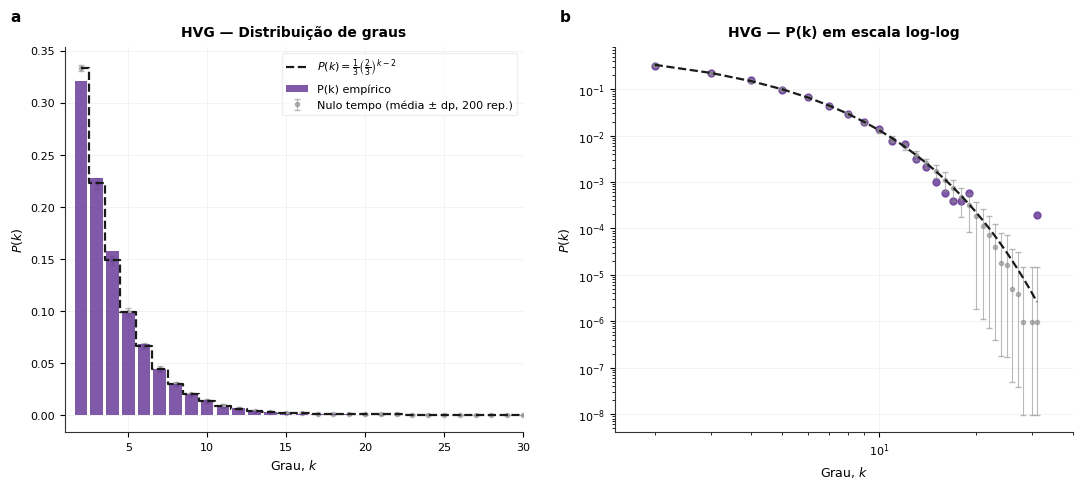

In [ ]:
graus_hvg = np.array([
    grau for _, grau in G_hvg.degree()
])

k_range = np.arange(
    2,
    graus_hvg.max() + 1
)

p_emp = np.array([
    (graus_hvg == k).mean()
    for k in k_range
])

p_theo = (
    (1 / 3) *
    (2 / 3) ** (k_range - 2)
)

rng_pk = np.random.default_rng(SEED_NULOS)
pk_nulo = np.zeros((N_REP_NULOS, len(k_range)))
for r in tqdm(range(N_REP_NULOS), desc="P(k) do nulo embaralhado"):
    y_emb = np.array(rng_pk.permutation(serie_temp_max), dtype=np.float64, copy=True)
    g_emb = HorizontalVG()
    g_emb.build(y_emb)
    arestas_emb = np.array([(a, b) for a, b, *_ in g_emb.edges])
    graus_emb = np.bincount(arestas_emb.ravel(), minlength=len(y_emb))
    dist_emb = np.bincount(graus_emb, minlength=k_range.max() + 1)
    pk_nulo[r] = dist_emb[k_range] / len(y_emb)

pk_med = pk_nulo.mean(axis=0)
pk_dp = pk_nulo.std(axis=0)

print(f"\n{'='*60}")
print("  VALIDAÇÃO P(k) — HVG VS. MODELO NULO")
print(f"{'='*60}")
print(f"Grau médio observado: {graus_hvg.mean():.4f}")
H_N = np.sum(1.0 / np.arange(1, len(graus_hvg) + 1))
k_teo_finito = 4 * (1 - H_N / len(graus_hvg))
print("Grau médio teórico no limite i.i.d.: 4.0000")
print(
    f"Grau médio teórico para N={len(graus_hvg)}: "
    f"{k_teo_finito:.4f}"
)
print(
    f"Desvio em relação ao limite 4: "
    f"{graus_hvg.mean() - 4.0:+.4f}"
)

print(f"\n{'k':>3} {'P_emp':>10} {'P_teórico':>12} {'Δ':>10} {'Nulo embaralhado (média ± dp)':>32} {'z':>7}")
for k, pe, pt, nm, nd in zip(
    k_range[:12],
    p_emp[:12],
    p_theo[:12],
    pk_med[:12],
    pk_dp[:12]
):
    print(
        f"{k:3d} {pe:10.4f} "
        f"{pt:12.4f} {pe - pt:+10.4f} "
        f"{nm:16.4f} ± {nd:.4f} {(pe - nm) / nd:+7.1f}"
    )

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

for ax in axes:
    estilizar_ax(ax)

axes[0].bar(
    k_range,
    p_emp,
    color=COR_HVG,
    alpha=0.85,
    edgecolor="none",
    zorder=3,
    width=0.8,
    label="P(k) empírico"
)

axes[0].step(
    k_range,
    p_theo,
    where="mid",
    color=COR_TEORICO,
    linestyle="--",
    linewidth=1.6,
    zorder=4,
    label=r"$P(k)=\frac{1}{3}\left(\frac{2}{3}\right)^{k-2}$"
)

axes[0].errorbar(
    k_range,
    pk_med,
    yerr=pk_dp,
    fmt="o",
    ms=3,
    color=COR_NULO,
    ecolor=COR_NULO,
    elinewidth=0.8,
    capsize=2,
    lw=0.8,
    alpha=0.6,
    zorder=2,
    label=f"Nulo tempo (média ± dp, {N_REP_NULOS} rep.)"
)

axes[0].set_xlim(
    1,
    min(30, k_range.max() + 1)
)
axes[0].set_xlabel("Grau, $k$")
axes[0].set_ylabel("$P(k)$")
axes[0].set_title(
    "HVG — Distribuição de graus",
    pad=8
)
axes[0].legend(fontsize=8)

mascara_log = p_emp > 0

axes[1].loglog(
    k_range[mascara_log],
    p_emp[mascara_log],
    "o",
    color=COR_HVG,
    ms=5,
    alpha=0.85,
    label="P(k) empírico"
)

axes[1].loglog(
    k_range,
    p_theo,
    "--",
    color=COR_TEORICO,
    lw=1.6,
    zorder=4,
    label="Modelo nulo i.i.d."
)

mascara_nulo = pk_med > 0
axes[1].errorbar(
    k_range[mascara_nulo],
    pk_med[mascara_nulo],
    yerr=[
        np.minimum(pk_dp[mascara_nulo], 0.99 * pk_med[mascara_nulo]),
        pk_dp[mascara_nulo]
    ],
    fmt="o",
    ms=3,
    color=COR_NULO,
    ecolor=COR_NULO,
    elinewidth=0.8,
    capsize=2,
    lw=0.8,
    alpha=0.6,
    zorder=2,
    label=f"Nulo embaralhado (média ± dp, {N_REP_NULOS} rep.)"
)

axes[1].set_xlabel("Grau, $k$")
axes[1].set_ylabel("$P(k)$")
axes[1].set_title(
    "HVG — P(k) em escala log-log",
    pad=8
)
axes[1].set_xlim(1.5, 40)

rotular_painel(axes[0], "a")
rotular_painel(axes[1], "b")

salvar_mostrar(
    fig,
    "parte1_validacao_pk.svg"
)

## 7.1 · Empates, desempate e modelos nulos


In [ ]:
def arestas_hvg(serie, estrito=True):
    y = np.array(serie, dtype=np.float64, copy=True)
    if estrito:
        g = HorizontalVG()
        g.build(y)
        return [(int(a), int(b)) for a, b, *_ in g.edges]
    arestas = []
    for i in range(len(y) - 1):
        m = -np.inf
        for j in range(i + 1, len(y)):
            if m <= min(y[i], y[j]):
                arestas.append((i, j))
            m = max(m, y[j])
            if m > y[i]:
                break
    return arestas


def grafo_de(arestas, n):
    G = nx.Graph()
    G.add_nodes_from(range(n))
    G.add_edges_from(arestas)
    return G


def metricas_rede(G):
    n = G.number_of_nodes()
    k = np.array([G.degree(i) for i in range(n)])
    tri = nx.triangles(G)
    T = np.array([tri[i] for i in range(n)])
    return {
        "arestas": G.number_of_edges(),
        "k_medio": k.mean(),
        "C_medio": nx.average_clustering(G),
        "transitividade": nx.transitivity(G),
        "P(2)": (k == 2).mean(),
        "k_max": int(k.max()),
        "nós com T < k-1": int(((T < k - 1) & (k > 1)).sum()),
        "hubs (k>=10)": int((k >= 10).sum()),
        "hubs (k>=10) abaixo de 2/k": int(((T < k - 1) & (k >= 10)).sum()),
    }


N = len(serie_temp_max)

print("Teste do critério (3,3,3):", arestas_hvg([3.0, 3.0, 3.0]))

comparacao = pd.DataFrame({
    "Com empates (estrito)": metricas_rede(G_hvg_emp),
    "Desempatada (estrito)": metricas_rede(G_hvg),
    "Variante não estrita (<=)": metricas_rede(
        grafo_de(arestas_hvg(serie_temp_max_bruta, estrito=False), N)
    ),
})
print(f"\n{'='*70}\n  HVG — EFEITO DOS EMPATES\n{'='*70}")
print(comparacao.round(4).to_string())

linhas = []
for sigma in (1e-8, 1e-6, 1e-4):
    for semente in range(30):
        r = np.random.default_rng(semente)
        m = metricas_rede(grafo_de(arestas_hvg(serie_temp_max_bruta + r.normal(0, sigma, N)), N))
        m.update(sigma=sigma, semente=semente)
        linhas.append(m)

sens_ruido = pd.DataFrame(linhas)
sens_ruido.to_csv(PROCESSED_DIR / "sensibilidade_ruido_hvg.csv", index=False)
print(f"\n{'='*70}\n  SENSIBILIDADE AO RUÍDO (média ± desvio, 30 sementes)\n{'='*70}")
print(
    sens_ruido.groupby("sigma")[["arestas", "k_medio", "C_medio", "transitividade"]]
    .agg(["mean", "std"])
    .round(4)
    .to_string()
)

Teste do critério (3,3,3): [(0, 1), (1, 2)]

  HVG — EFEITO DOS EMPATES
                            Com empates (estrito)  Desempatada (estrito)  Variante não estrita (<=)
arestas                                 9287.0000             10204.0000                 11393.0000
k_medio                                    3.6320                 3.9906                     4.4556
C_medio                                    0.5417                 0.6426                     0.6777
transitividade                             0.3055                 0.3407                     0.3824
P(2)                                       0.3528                 0.3207                     0.2871
k_max                                     24.0000                31.0000                    38.0000
nós com T < k-1                         2149.0000                21.0000                     7.0000
hubs (k>=10)                              77.0000               185.0000                   339.0000
hubs (k>=10) abaixo de 2/k  

In [ ]:
def metricas_basicas(serie):
    G = grafo_de(arestas_hvg(serie), len(serie))
    k = np.array([G.degree(i) for i in range(len(serie))])
    return [
        2 * G.number_of_edges() / len(serie),
        nx.average_clustering(G),
        nx.transitivity(G),
        (k == 2).mean(),
        (k == 3).mean(),
    ]


NOMES_MET = ["k_medio", "C_medio", "transitividade", "P(2)", "P(3)"]

t_idx = np.arange(N)
ang = df_recorte["data"].dt.dayofyear.to_numpy() * 2 * np.pi / 365.25
X_sazonal = np.column_stack(
    [np.ones(N)]
    + [f(h * ang) for h in (1, 2, 3) for f in (np.sin, np.cos)]
    + [t_idx / N]
)
beta = np.linalg.lstsq(X_sazonal, serie_temp_max_bruta, rcond=None)[0]
anomalias = serie_temp_max_bruta - X_sazonal @ beta
print(f"Variância explicada por sazonalidade + tendência: {1 - anomalias.var() / serie_temp_max_bruta.var():.3f}")
print(f"Tendência ajustada no período: {beta[-1]:+.2f} °C")

rng_nulo = np.random.default_rng(SEED_NULOS)


def surrogate_fase(x):
    f = np.fft.rfft(x - x.mean())
    fase = rng_nulo.uniform(0, 2 * np.pi, len(f))
    fase[0] = 0
    if len(x) % 2 == 0:
        fase[-1] = 0
    return np.fft.irfft(np.abs(f) * np.exp(1j * fase), n=len(x)) + x.mean()


geradores_nulo = {
    "Embaralhada (mesmos valores e empates)": lambda: rng_nulo.permutation(serie_temp_max_bruta),
    "Embaralhada desempatada": lambda: rng_nulo.permutation(serie_temp_max),
    "Embaralhada das anomalias": lambda: rng_nulo.permutation(anomalias),
    "Fase aleatória das anomalias": lambda: surrogate_fase(anomalias),
    "Fase aleatória da série bruta (desempatada)": lambda: surrogate_fase(serie_temp_max_bruta) + rng_nulo.normal(0, SIGMA_DESEMPATE, N),
}

observados = {
    "Série com empates": metricas_basicas(serie_temp_max_bruta),
    "Série desempatada": metricas_basicas(serie_temp_max),
    "Anomalias": metricas_basicas(anomalias),
}

amostras_nulo = {}
for nome, gerar in tqdm(geradores_nulo.items(), desc="Nulos"):
    amostras_nulo[nome] = np.array([metricas_basicas(gerar()) for _ in range(N_REP_NULOS)])

linhas = [{"modelo": nome, "tipo": "observado", **dict(zip(NOMES_MET, v))} for nome, v in observados.items()]
for nome, a in amostras_nulo.items():
    linhas.append({"modelo": nome, "tipo": "média", **dict(zip(NOMES_MET, a.mean(0)))})
    linhas.append({"modelo": nome, "tipo": "desvio", **dict(zip(NOMES_MET, a.std(0)))})
H_N = np.sum(1.0 / np.arange(1, N + 1))
linhas.append({"modelo": "Teórico i.i.d. contínuo", "tipo": "teórico", "k_medio": 4 * (1 - H_N / N), "P(2)": 1 / 3, "P(3)": 2 / 9})
tabela_nulos = pd.DataFrame(linhas)
tabela_nulos.to_csv(PROCESSED_DIR / "nulos_hvg.csv", index=False)

print(f"\n{'='*80}\n  HVG — SÉRIE REAL VS. MODELOS NULOS ({N_REP_NULOS} repetições)\n{'='*80}")
print(tabela_nulos.round(4).to_string(index=False))

pares = [
    ("Série com empates", "Embaralhada (mesmos valores e empates)"),
    ("Série desempatada", "Embaralhada desempatada"),
    ("Anomalias", "Embaralhada das anomalias"),
    ("Anomalias", "Fase aleatória das anomalias"),
    ("Série desempatada", "Fase aleatória da série bruta (desempatada)"),
]
print("\nEscores z (observado − média do nulo) / desvio do nulo:")
linhas_z = []
for obs, nulo in pares:
    a = amostras_nulo[nulo]
    z = (np.array(observados[obs]) - a.mean(0)) / a.std(0)
    linhas_z.append({"observado": obs, "nulo": nulo, **dict(zip(NOMES_MET, z))})
print(pd.DataFrame(linhas_z).round(1).to_string(index=False))

Variância explicada por sazonalidade + tendência: 0.444
Tendência ajustada no período: +0.42 °C



  HVG — SÉRIE REAL VS. MODELOS NULOS (200 repetições)
                                     modelo      tipo  k_medio  C_medio  transitividade   P(2)   P(3)
                          Série com empates observado   3.6320   0.5417          0.3055 0.3528 0.2534
                          Série desempatada observado   3.9906   0.6426          0.3407 0.3207 0.2274
                                  Anomalias observado   3.9922   0.6429          0.3390 0.3185 0.2323
     Embaralhada (mesmos valores e empates)     média   3.8105   0.6054          0.3222 0.3460 0.2297
     Embaralhada (mesmos valores e empates)    desvio   0.0070   0.0032          0.0017 0.0031 0.0055
                    Embaralhada desempatada     média   3.9931   0.6478          0.3352 0.3335 0.2226
                    Embaralhada desempatada    desvio   0.0013   0.0010          0.0015 0.0031 0.0047
                  Embaralhada das anomalias     média   3.9930   0.6478          0.3352 0.3336 0.2222
                  Embaralha

A diferença entre $\langle k\rangle \approx 3{,}63$ e 4,0 vem dos empates; o nulo correto com empates (série embaralhada com os mesmos valores) já dá $\approx 3{,}81$.
Depois do desempate, $\langle k\rangle$ da série real fica próximo do nulo embaralhado, de modo que $\langle k\rangle$ sozinho não discrimina a série real de uma série aleatória.
A diferença aparece em $\langle C\rangle$ e $P(2)$ (estrutura temporal). Os surrogates de fase, que preservam apenas a autocorrelação linear, reproduzem $\langle k\rangle$ e $\langle C\rangle$ da série real; portanto,
estas métricas não mostram evidência de dinâmica não linear, e remover sazonalidade e tendência quase não altera a topologia.

## 8 · Locais de visibilidade e comparação com ondas de calor

- pico isolado em **26/11/2013**;
- onda de calor CTX90pct centrada em **15/03/2010**.

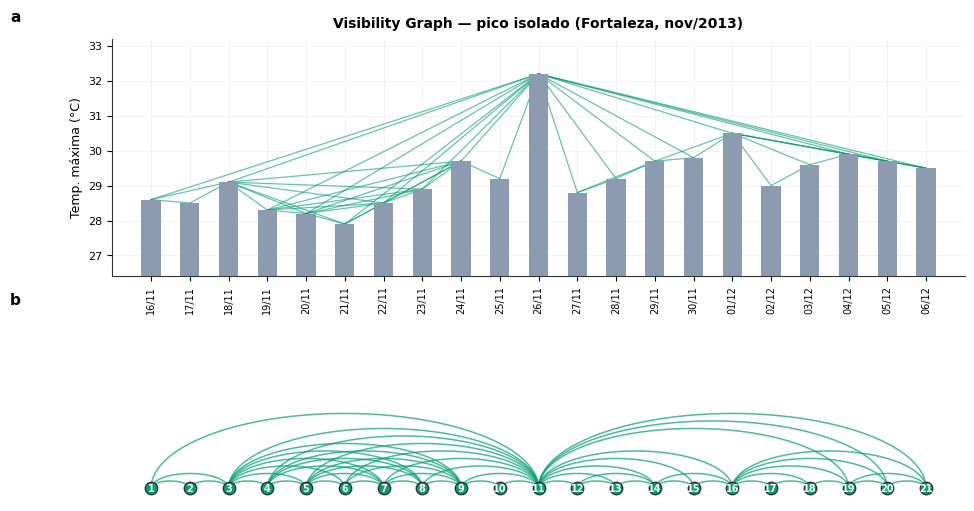

[OK] vg_exemplo_pico_isolado.svg — 56 arestas locais


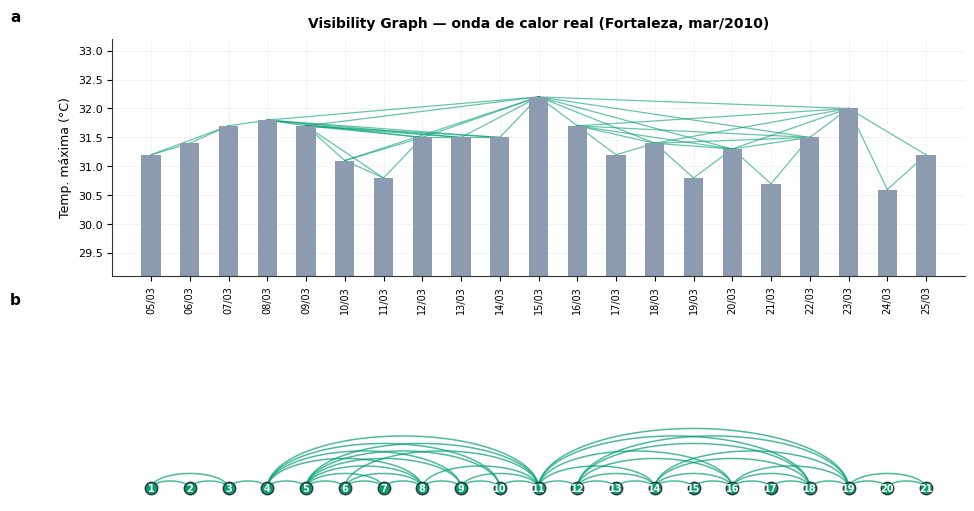

[OK] vg_exemplo_onda_calor.svg — 48 arestas locais


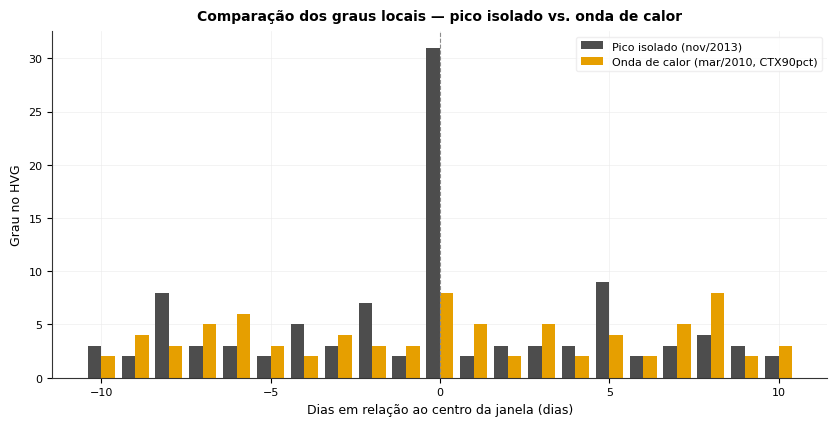

In [ ]:
def idx_da_data(data):
    data = pd.Timestamp(data)
    indices = df_recorte.index[
        df_recorte["data"] == data
    ]

    if len(indices) == 0:
        raise ValueError(
            f"Data {data.date()} não encontrada no recorte."
        )

    return int(indices[0])


def plot_estilo_lacasa(
    indices,
    titulo,
    arquivo_svg,
    G
):
    n = len(indices)
    x = np.arange(n)
    y = serie_temp_max[indices]

    sub = G.subgraph(indices)
    mapa = {
        no_global: no_local
        for no_local, no_global in enumerate(indices)
    }

    arestas_locais = [
        (mapa[u], mapa[v])
        for u, v in sub.edges()
    ]

    fig, (ax_bar, ax_arc) = plt.subplots(
        2,
        1,
        figsize=(11, 6),
        height_ratios=[1.3, 1]
    )

    for ax in (ax_bar, ax_arc):
        estilizar_ax(ax)

    base = y.min() - 1.5

    ax_bar.bar(
        x,
        y - base,
        bottom=base,
        width=0.5,
        color=COR_TEMP,
        zorder=2
    )

    for i, j in arestas_locais:
        ax_bar.plot(
            [x[i], x[j]],
            [y[i], y[j]],
            color=COR_NVG,
            linewidth=0.9,
            alpha=0.6,
            zorder=1
        )

    ax_bar.set_xlim(-1, n)
    ax_bar.set_ylim(base, y.max() + 1)
    ax_bar.set_ylabel("Temp. máxima (°C)")
    ax_bar.set_xticks(x)
    ax_bar.set_xticklabels(
        [
            df_recorte["data"].iloc[i].strftime("%d/%m")
            for i in indices
        ],
        rotation=90,
        fontsize=7
    )
    ax_bar.set_title(titulo, pad=8, fontweight="bold")
    rotular_painel(ax_bar, "a")
    rotular_painel(ax_arc, "b")

    ax_arc.scatter(
        x,
        np.zeros(n),
        s=80,
        color=COR_NVG,
        edgecolor=BORDA,
        zorder=3
    )

    for posicao, lbl in enumerate(x):
        ax_arc.annotate(
            str(posicao + 1),
            (lbl, 0),
            ha="center",
            va="center",
            fontsize=7,
            fontweight="bold",
            zorder=4,
            color="white"
        )

    for i, j in arestas_locais:
        centro = (x[i] + x[j]) / 2
        raio = abs(x[j] - x[i]) / 2
        theta = np.linspace(0, np.pi, 60)

        ax_arc.plot(
            centro + raio * np.cos(theta),
            raio * np.sin(theta) * 0.6,
            color=COR_NVG,
            linewidth=1.1,
            alpha=0.7,
            zorder=2
        )

    ax_arc.set_xlabel("Dia na janela (dias)")
    ax_arc.set_xlim(-1, n)
    ax_arc.set_ylim(
        -0.5,
        (n / 2) * 0.6 + 0.5
    )
    ax_arc.axis("off")

    salvar_mostrar(
        fig,
        arquivo_svg
    )

    print(
        f"[OK] {arquivo_svg} — "
        f"{len(arestas_locais)} arestas locais"
    )


centro1 = idx_da_data("2013-11-26")
janela1 = list(range(centro1 - 10, centro1 + 11))

centro2 = idx_da_data("2010-03-15")
janela2 = list(range(centro2 - 10, centro2 + 11))

plot_estilo_lacasa(
    janela1,
    "Visibility Graph — pico isolado (Fortaleza, nov/2013)",
    "vg_exemplo_pico_isolado.svg",
    G_nvg
)

plot_estilo_lacasa(
    janela2,
    "Visibility Graph — onda de calor real (Fortaleza, mar/2010)",
    "vg_exemplo_onda_calor.svg",
    G_nvg
)

graus_hvg_dict = dict(G_hvg.degree())
offsets = np.arange(-10, 11)

fig, ax = plt.subplots(
    figsize=(10, 4.5)
)
estilizar_ax(ax)

largura = 0.4

ax.bar(
    offsets - largura / 2,
    [graus_hvg_dict[i] for i in janela1],
    width=largura,
    color=COR_PICO,
    label="Pico isolado (nov/2013)"
)

ax.bar(
    offsets + largura / 2,
    [graus_hvg_dict[i] for i in janela2],
    width=largura,
    color=COR_CALOR,
    label="Onda de calor (mar/2010, CTX90pct)"
)

ax.axvline(
    0,
    color=COR_NULO,
    linewidth=0.8,
    linestyle="--"
)

ax.set_xlabel("Dias em relação ao centro da janela (dias)")
ax.set_ylabel("Grau no HVG")
ax.set_title(
    "Comparação dos graus locais — pico isolado vs. onda de calor",
    pad=8
)
ax.legend()

salvar_mostrar(
    fig,
    "comparacao_hub_repulsion.svg"
)

## 9 · Série completa e grau dos nós

A série de temperatura máxima é representada juntamente com o grau do nó correspondente no HVG. A cor dos pontos representa o grau em escala logarítmica, permitindo localizar visualmente os dias de maior conectividade.

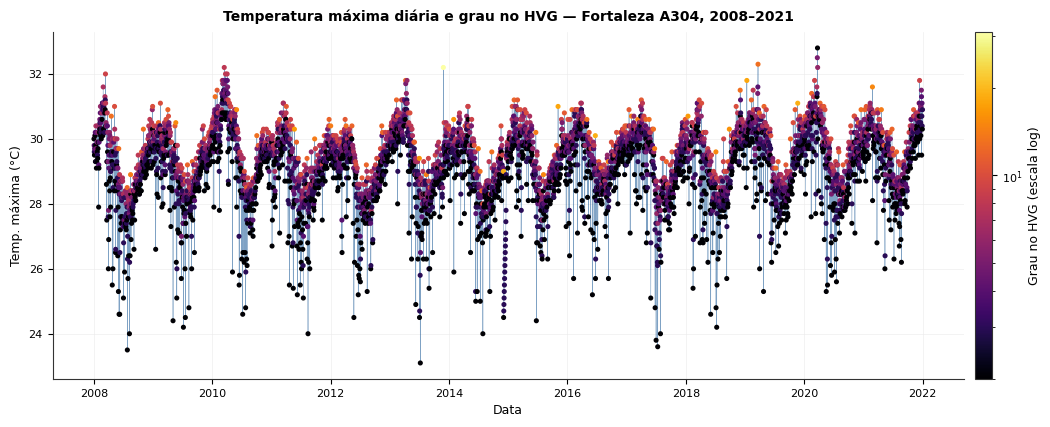

In [ ]:
graus_hvg_arr = np.array([
    grau for _, grau in G_hvg.degree()
])

fig, ax = plt.subplots(
    figsize=(14, 4.5)
)
estilizar_ax(ax)

ax.plot(df_recorte["data"], serie_temp_max, color=COR_SERIE, linewidth=0.4, alpha=0.5, zorder=1)
sc = ax.scatter(df_recorte["data"], serie_temp_max, c=graus_hvg_arr, cmap="inferno",
                norm=mcolors.LogNorm(vmin=max(1, graus_hvg_arr.min()), vmax=graus_hvg_arr.max()),
                s=7, zorder=2)

cbar = plt.colorbar(
    sc,
    ax=ax,
    pad=0.01
)
cbar.set_label(
    "Grau no HVG (escala log)",
    color=TEXTO,
    fontsize=9
)
cbar.ax.yaxis.set_tick_params(
    color=TEXTO
)
plt.setp(
    cbar.ax.yaxis.get_ticklabels(),
    color=TEXTO
)

ax.set_xlabel("Data")
ax.set_ylabel("Temp. máxima (°C)")
ax.set_title(
    "Temperatura máxima diária e grau no HVG — Fortaleza A304, 2008–2021",
    pad=8
)

salvar_mostrar(
    fig,
    "serie_completa_com_graus.svg"
)

# PARTE II — Análise Estrutural da Rede

Nesta etapa, HVG e NVG são analisados com as mesmas métricas para permitir comparação direta.

A densidade é

$$
\rho = \frac{2E}{N(N-1)}.
$$

A conectividade é verificada explicitamente, e a maior componente conexa é identificada. Para os Visibility Graphs construídos sobre a série completa, a conectividade esperada é preservada pelas conexões entre observações consecutivas.

In [ ]:
def distribuicao_caminhos(G):
    """Distribuição de distâncias geodésicas, excluindo distância zero."""
    contagem = Counter()

    for no in G.nodes():
        contagem.update(
            nx.single_source_shortest_path_length(
                G,
                no
            ).values()
        )

    contagem.pop(0, None)
    return contagem


def componente_para_distancias(G):
    """
    Usa a rede inteira quando conectada.
    Se houver mais de uma componente, usa a maior componente conexa
    para calcular distâncias sem produzir métricas indefinidas.
    """
    if nx.is_connected(G):
        return G, 1.0

    componente = max(
        nx.connected_components(G),
        key=len
    )

    G_gigante = G.subgraph(
        componente
    ).copy()

    fracao = (
        G_gigante.number_of_nodes() /
        G.number_of_nodes()
    )

    return G_gigante, fracao


resultados = {}

for nome, G in (
    ("HVG", G_hvg),
    ("NVG", G_nvg)
):
    N = G.number_of_nodes()
    E = G.number_of_edges()
    densidade = nx.density(G)

    componentes = list(
        nx.connected_components(G)
    )

    tamanhos = sorted(
        [len(c) for c in componentes],
        reverse=True
    )

    G_dist, fracao_gigante = componente_para_distancias(G)

    graus = np.array([
        grau for _, grau in G.degree()
    ])

    agrupamento_medio = nx.average_clustering(G)
    transitividade = nx.transitivity(G)

    valores_k, contagens_k = np.unique(
        graus,
        return_counts=True
    )

    p_k = contagens_k / contagens_k.sum()

    mascara_cauda = (
        (valores_k >= 5) &
        (p_k > 0)
    )

    if mascara_cauda.sum() >= 2:
        slope, _, r_value, _, _ = sp_stats.linregress(
            np.log(valores_k[mascara_cauda]),
            np.log(p_k[mascara_cauda])
        )
        alpha = -slope
        r2 = r_value ** 2
    else:
        alpha = np.nan
        r2 = np.nan

    contagem = distribuicao_caminhos(G_dist)
    n_pares = sum(contagem.values())

    media_caminho = (
        sum(
            distancia * quantidade
            for distancia, quantidade in contagem.items()
        ) / n_pares
    )

    diametro = max(contagem)

    resultados[nome] = {
        "N": N,
        "E": E,
        "densidade": densidade,
        "n_componentes": len(componentes),
        "tamanho_gigante": tamanhos[0],
        "fracao_gigante": fracao_gigante,
        "graus": graus,
        "agrupamento_medio": agrupamento_medio,
        "transitividade": transitividade,
        "contagem_caminhos": contagem,
        "media_caminho": media_caminho,
        "diametro": diametro,
        "alpha_cauda": alpha,
        "r2_cauda": r2,
    }

    print(f"\n{'='*60}")
    print(f"  PARTE II — {nome}")
    print(f"{'='*60}")
    print(f"Nós (N): {N}")
    print(f"Arestas (E): {E}")
    print(
        f"Densidade: {densidade:.8f} "
        f"({densidade * 100:.4f}%)"
    )
    print(f"Componentes conexas: {len(componentes)}")
    print(
        f"Maior componente: {tamanhos[0]} nós "
        f"({fracao_gigante * 100:.2f}% da rede)"
    )
    print(f"Grau médio: {graus.mean():.4f}")
    print(f"Grau mínimo: {graus.min()}")
    print(f"Grau máximo: {graus.max()}")
    print(
        f"Agrupamento médio <C>: "
        f"{agrupamento_medio:.4f}"
    )
    print(
        f"Transitividade: "
        f"{transitividade:.4f}"
    )
    print(
        f"Caminho mínimo médio <L>: "
        f"{media_caminho:.4f}"
    )
    print(f"Diâmetro D: {diametro}")

    if np.isfinite(alpha):
        print(
            f"Ajuste log-log da cauda (k >= 5): "
            f"alpha={alpha:.2f}; R²={r2:.3f}"
        )
    else:
        print(
            "Ajuste log-log da cauda: "
            "pontos insuficientes."
        )


  PARTE II — HVG
Nós (N): 5114
Arestas (E): 10204
Densidade: 0.00078048 (0.0780%)
Componentes conexas: 1
Maior componente: 5114 nós (100.00% da rede)
Grau médio: 3.9906
Grau mínimo: 2
Grau máximo: 31
Agrupamento médio <C>: 0.6426
Transitividade: 0.3407
Caminho mínimo médio <L>: 14.1404
Diâmetro D: 34
Ajuste log-log da cauda (k >= 5): alpha=4.16; R²=0.939

  PARTE II — NVG
Nós (N): 5114
Arestas (E): 17278
Densidade: 0.00132156 (0.1322%)
Componentes conexas: 1
Maior componente: 5114 nós (100.00% da rede)
Grau médio: 6.7571
Grau mínimo: 2
Grau máximo: 134
Agrupamento médio <C>: 0.7469
Transitividade: 0.3383
Caminho mínimo médio <L>: 5.7112
Diâmetro D: 11
Ajuste log-log da cauda (k >= 5): alpha=2.46; R²=0.934


## 10 · Distribuição de graus \(P(k)\): HVG e NVG

A distribuição de graus é comparada para as duas construções de Visibility Graph. A visualização principal usa escala log-log, com o objetivo de examinar a cauda e a presença de hubs.

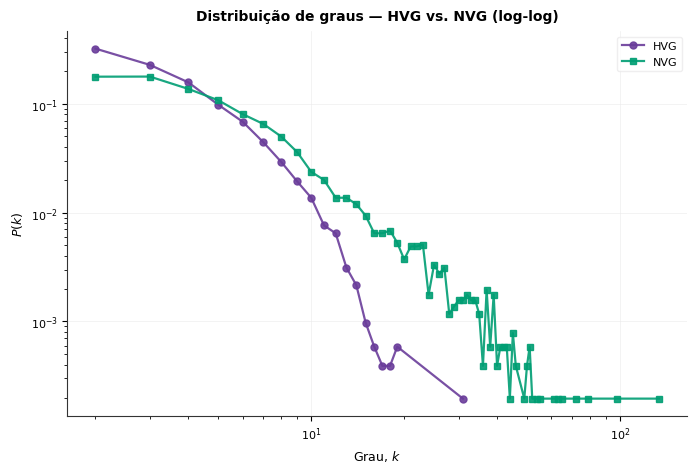

In [ ]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)
estilizar_ax(ax)

for nome, cor in CORES_REDE.items():
    graus = resultados[nome]["graus"]

    valores, contagens = np.unique(
        graus,
        return_counts=True
    )

    pk = contagens / contagens.sum()

    mascara = (
        (valores > 0) &
        (pk > 0)
    )

    ax.loglog(
        valores[mascara],
        pk[mascara],
        linestyle="-",
        marker=MARCADOR_REDE[nome],
        color=cor,
        markersize=5,
        linewidth=1.6,
        alpha=0.9,
        label=nome
    )

ax.set_xlabel("Grau, $k$")
ax.set_ylabel("$P(k)$")
ax.set_title(
    "Distribuição de graus — HVG vs. NVG (log-log)",
    pad=8
)
ax.legend(fontsize=8)

salvar_mostrar(
    fig,
    "parte2_distribuicao_grau_loglog.svg"
)

## 11 · Transitividade e coeficiente de agrupamento local

A **transitividade** é uma medida global baseada em triângulos e triplas conectadas. O **coeficiente de agrupamento local** \(C_i\) mede a conectividade entre os vizinhos de cada nó.

O gráfico \(C(k)\) versus \(k\) é mostrado para HVG e NVG. A curva \(C(k)=2/k\) é um **teto geométrico** do HVG (Luque et al., 2009): um nó de grau $k$ tem no máximo $k-1$ triângulos, o que ocorre quando seus vizinhos mais próximos à esquerda e à direita são limítrofes (mais altos). O HVG não *obedece* à curva por ser aleatório: ele fica sobre ela quando não há empates e abaixo dela quando há. Para o NVG não existe expectativa teórica de seguir $2/k$; a curva é só referência.

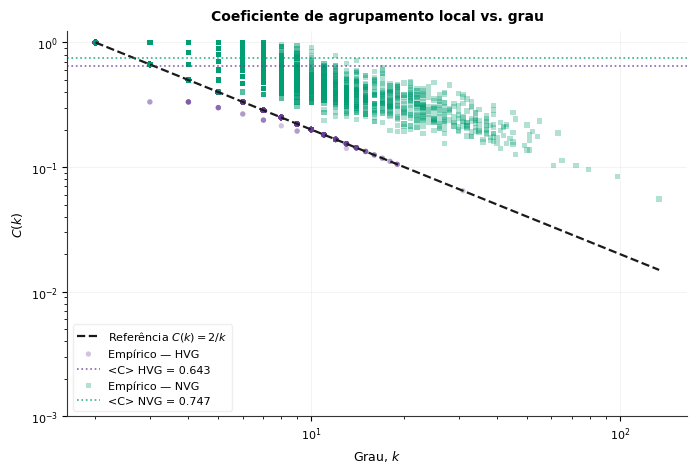

In [ ]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)
estilizar_ax(ax)

k_max_global = max(
    resultados[nome]["graus"].max()
    for nome in resultados
)

k_teo = np.linspace(
    2,
    k_max_global,
    300
)

ax.loglog(
    k_teo,
    2 / k_teo,
    "--",
    color=COR_TEORICO,
    linewidth=1.6,
    label=r"Referência $C(k)=2/k$"
)

for nome, cor in CORES_REDE.items():
    G = G_hvg if nome == "HVG" else G_nvg

    graus_dict = dict(G.degree())
    clustering_dict = nx.clustering(G)

    dados = [
        (graus_dict[no], clustering_dict[no])
        for no in G.nodes()
        if graus_dict[no] > 1
        and clustering_dict[no] > 0
    ]

    if dados:
        k_arr = np.array([
            item[0] for item in dados
        ])
        c_arr = np.array([
            item[1] for item in dados
        ])

        ax.scatter(
            k_arr,
            c_arr,
            alpha=0.3,
            s=15,
            marker=MARCADOR_REDE[nome],
            color=cor,
            edgecolor="none",
            label=f"Empírico — {nome}"
        )

    ax.axhline(
        resultados[nome]["agrupamento_medio"],
        color=cor,
        linewidth=1.2,
        linestyle=":",
        alpha=0.8,
        label=(
            f"<C> {nome} = "
            f"{resultados[nome]['agrupamento_medio']:.3f}"
        )
    )

ax.set_xlabel("Grau, $k$")
ax.set_ylabel("$C(k)$")
ax.set_title(
    "Coeficiente de agrupamento local vs. grau",
    pad=8
)
ax.set_ylim(bottom=1e-3)
ax.legend(fontsize=8)

salvar_mostrar(
    fig,
    "parte2_clustering_ck_vs_k.svg"
)

### 11.1 · $C(k)$ médio antes e depois do desempate

O gráfico mostra o $C(k)$ médio por grau, para a série com empates e para a desempatada. No HVG, os nós de **borda** são os que ficam abaixo do teto geométrico, isto é, com $T < k-1$ e $k > 1$ ($T$ = número de triângulos do nó). Eles são excluídos da média do HVG desempatado e marcados à parte (×), porque são o efeito de borda (nós sem limítrofe mais alto de um lado). Para o NVG não há teto teórico, e todos os nós entram na média.

HVG desempatado: 21 nós de borda, (T < k-1) & (k > 1) | nós com T > k-1: 0
Nós de borda (data, k, T): [('2008-01-07', 5, 3), ('2008-01-09', 4, 2), ('2008-01-11', 4, 2), ('2008-01-13', 7, 5), ('2008-01-27', 7, 5), ('2008-02-06', 5, 3), ('2008-02-09', 4, 2), ('2008-02-10', 6, 4), ('2008-02-22', 3, 1), ('2008-02-23', 3, 1), ('2008-02-27', 7, 5), ('2008-03-12', 9, 7), ('2010-03-15', 8, 6), ('2019-03-22', 13, 11), ('2020-03-22', 5, 3), ('2020-03-23', 2, 0), ('2020-03-24', 6, 4), ('2021-12-13', 9, 7), ('2021-12-24', 5, 3), ('2021-12-25', 4, 2), ('2021-12-28', 4, 2)]


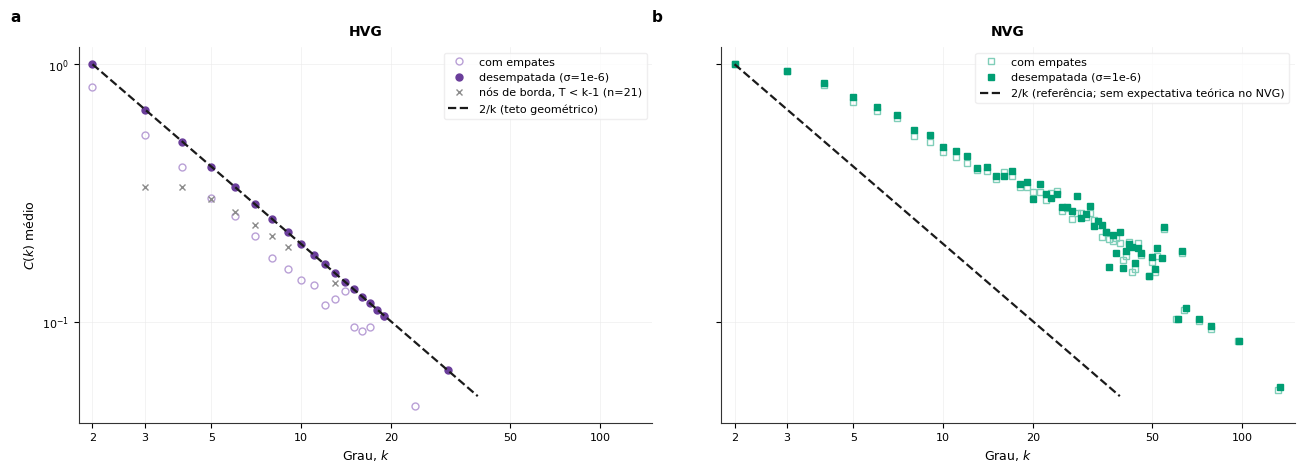

In [ ]:
def ck_por_no(G):
    n = G.number_of_nodes()
    k = np.array([G.degree(i) for i in range(n)])
    tri = nx.triangles(G)
    T = np.array([tri[i] for i in range(n)])
    C = np.where(k > 1, T / np.maximum(k * (k - 1) / 2, 1), 0.0)
    return k, T, C


# Critério de borda: exatamente (T < k - 1) & (k > 1), no HVG desempatado.
k_hd, T_hd, _ = ck_por_no(G_hvg)
borda_hvg_des = (T_hd < k_hd - 1) & (k_hd > 1)
assert int(borda_hvg_des.sum()) == metricas_rede(G_hvg)["nós com T < k-1"]
print(f"HVG desempatado: {int(borda_hvg_des.sum())} nós de borda, (T < k-1) & (k > 1) | "
      f"nós com T > k-1: {int((T_hd > k_hd - 1).sum())}")
print("Nós de borda (data, k, T):", [(str(df_recorte['data'].iloc[i].date()), int(k_hd[i]), int(T_hd[i])) for i in np.where(borda_hvg_des)[0]])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
kk = np.arange(2, 40)

for ax, nome, G_emp, G_des in (
    (axes[0], "HVG", G_hvg_emp, G_hvg),
    (axes[1], "NVG", G_nvg_emp, G_nvg),
):
    estilizar_ax(ax)

    for G, rotulo, cor, marcador, vazado in (
        (G_emp, "com empates", CORES_REDE_CLARO[nome], MARCADOR_REDE[nome], True),
        (G_des, "desempatada (σ=1e-6)", CORES_REDE[nome], MARCADOR_REDE[nome], False),
    ):
        k, T, C = ck_por_no(G)
        ks = np.unique(k[k > 1])
        excluir = borda_hvg_des if (nome == "HVG" and not vazado) else np.zeros(len(k), dtype=bool)
        medias = [C[(k == j) & ~excluir].mean() if ((k == j) & ~excluir).any() else np.nan for j in ks]
        ax.plot(ks, medias, marcador, color=cor, ms=5, mfc="none" if vazado else cor, label=rotulo)

        if nome == "HVG" and not vazado:
            bmed = [C[(k == j) & excluir].mean() if ((k == j) & excluir).any() else np.nan for j in ks]
            ax.plot(ks, bmed, "x", color=COR_NULO, ms=5, label=f"nós de borda, T < k-1 (n={int(excluir.sum())})")

    if nome == "HVG":
        ax.plot(kk, 2 / kk, "--", color=COR_TEORICO, lw=1.6, label="2/k (teto geométrico)")
    else:
        ax.plot(kk, 2 / kk, "--", color=COR_TEORICO, lw=1.6, label="2/k (referência; sem expectativa teórica no NVG)")

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xticks([2, 3, 5, 10, 20, 50, 100])
    ax.set_xticklabels(["2", "3", "5", "10", "20", "50", "100"])
    ax.minorticks_off()
    ax.set_xlim(1.8, 150)
    ax.set_xlabel("Grau, $k$")
    ax.set_title(nome, pad=8)
    rotular_painel(ax, "a" if nome == "HVG" else "b")
    ax.legend(fontsize=8)

axes[0].set_ylabel("$C(k)$ médio")
plt.tight_layout()
salvar_mostrar(fig, "parte2_clustering_ck_antes_depois.svg")

## 12 · Distâncias geodésicas, caminho mínimo médio e diâmetro


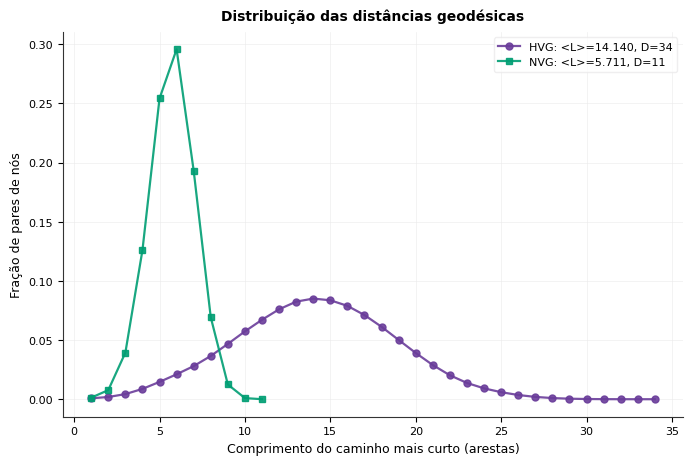

In [ ]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)
estilizar_ax(ax)

for nome, cor in CORES_REDE.items():
    contagem = resultados[nome]["contagem_caminhos"]

    distancias = sorted(
        contagem.keys()
    )

    total = sum(
        contagem.values()
    )

    frequencias = [
        contagem[d] / total
        for d in distancias
    ]

    ax.plot(
        distancias,
        frequencias,
        linestyle="-",
        linewidth=1.6,
        marker=MARCADOR_REDE[nome],
        color=cor,
        markersize=5,
        alpha=0.9,
        label=(
            f"{nome}: "
            f"<L>={resultados[nome]['media_caminho']:.3f}, "
            f"D={resultados[nome]['diametro']}"
        )
    )

ax.set_xlabel(
    "Comprimento do caminho mais curto (arestas)"
)
ax.set_ylabel(
    "Fração de pares de nós"
)
ax.set_title(
    "Distribuição das distâncias geodésicas",
    pad=8
)
ax.legend(fontsize=8)

salvar_mostrar(
    fig,
    "parte2_distancias_geodesicas.svg"
)

### 12.1 · Comparação com redes de referência (small-world)

Para HVG e NVG, comparam-se $\langle L\rangle$ e $\langle C\rangle$ com (i) grafos aleatórios de Erdős–Rényi com o mesmo $N$ e $E$, (ii) redes reconfiguradas que preservam o grau (trocas de arestas) e
(iii) o HVG/NVG de séries embaralhadas. Calculam-se

$$\sigma = \frac{C/C_r}{L/L_r}, \qquad \omega = \frac{L_r}{L} - \frac{C}{C_\ell},$$

com $C_\ell = 3(\langle k\rangle-2)/\left(4(\langle k\rangle-1)\right)$ para a rede regular. Como Visibility Graphs têm $\langle C\rangle$ alto por construção
(inclusive para séries embaralhadas), $\sigma$ sozinho superestima a propriedade small-world; $\omega$ e a comparação com séries embaralhadas são mais informativos.

In [ ]:
def caminho_medio(G):
    A = nx.to_scipy_sparse_array(G, format="csr")
    D = shortest_path(A, method="D", unweighted=True, directed=False)
    return D[np.isfinite(D) & (D > 0)].mean()


def componente_gigante(G):
    return G.subgraph(max(nx.connected_components(G), key=len)).copy()


rng_sw = np.random.default_rng(11)
N_REP_SW = 5
linhas_sw = []

for nome, G in (
    ("HVG desempatado", G_hvg),
    ("NVG desempatado", G_nvg),
    ("HVG com empates", G_hvg_emp),
    ("NVG com empates", G_nvg_emp),
):
    m = G.number_of_edges()
    k_medio = 2 * m / N
    L = caminho_medio(G)
    C = nx.average_clustering(G)

    er, rw = [], []
    for _ in range(N_REP_SW):
        Ge = componente_gigante(nx.gnm_random_graph(N, m, seed=int(rng_sw.integers(1e9))))
        er.append((caminho_medio(Ge), nx.average_clustering(Ge)))

        Gr = G.copy()
        nx.double_edge_swap(Gr, nswap=10 * m, max_tries=100 * m, seed=int(rng_sw.integers(1e9)))
        Gr = componente_gigante(Gr)
        rw.append((caminho_medio(Gr), nx.average_clustering(Gr)))

    er, rw = np.array(er).mean(0), np.array(rw).mean(0)
    C_reg = 3 * (k_medio - 2) / (4 * (k_medio - 1))

    linhas_sw.append({
        "rede": nome, "<k>": k_medio, "<L>": L,
        "ln N/ln<k>": np.log(N) / np.log(k_medio),
        "<L> ER": er[0], "<L> reconf.": rw[0],
        "<C>": C, "<C> ER": er[1], "<C> reconf.": rw[1], "<C> regular": C_reg,
        "sigma (ER)": (C / er[1]) / (L / er[0]),
        "sigma (reconf.)": (C / rw[1]) / (L / rw[0]),
        "omega (ER)": er[0] / L - C / C_reg,
        "omega (reconf.)": rw[0] / L - C / C_reg,
    })

tabela_sw = pd.DataFrame(linhas_sw)
tabela_sw.to_csv(PROCESSED_DIR / "mundo_pequeno.csv", index=False)
print(f"\n{'='*80}\n  SMALL-WORLD — REDES DE REFERÊNCIA ({N_REP_SW} repetições)\n{'='*80}")
print(tabela_sw.round(3).T.to_string(header=False))

# Séries embaralhadas (desempatadas): L e C esperados sem estrutura temporal.
for nome, construir in (
    ("HVG", lambda v: grafo_de(arestas_hvg(v), N)),
    ("NVG", lambda v: grafo_de([(int(a), int(b)) for a, b, *_ in NaturalVG().build(np.array(v, dtype=float)).edges], N)),
):
    amostra = []
    for _ in range(N_REP_SW):
        Gs = construir(rng_sw.permutation(serie_temp_max))
        amostra.append((caminho_medio(Gs), nx.average_clustering(Gs)))
    amostra = np.array(amostra)
    print(
        f"{nome} de série embaralhada: <L> = {amostra[:, 0].mean():.2f} ± {amostra[:, 0].std():.2f}; "
        f"<C> = {amostra[:, 1].mean():.3f} ± {amostra[:, 1].std():.3f}  "
        f"(real: <L> = {resultados[nome]['media_caminho']:.2f}; <C> = {resultados[nome]['agrupamento_medio']:.3f})"
    )


  SMALL-WORLD — REDES DE REFERÊNCIA (5 repetições)
rede             HVG desempatado  NVG desempatado  HVG com empates  NVG com empates
<k>                        3.991            6.757            3.632            6.594
<L>                        14.14            5.711           16.832            5.744
ln N/ln<k>                 6.171             4.47            6.621            4.527
<L> ER                     6.288            4.687            6.709             4.74
<L> reconf.                 6.11            4.164            6.735            4.198
<C>                        0.643            0.747            0.542             0.74
<C> ER                     0.001            0.001              0.0            0.001
<C> reconf.                0.001            0.005            0.001            0.005
<C> regular                0.499             0.62            0.465            0.616
sigma (ER)               564.292           468.33          529.082          475.092
sigma (reconf.)         

## 13 · Cruzamento físico-topológico: Top 15 hubs do HVG e do NVG

Os nós são ordenados pelo grau, em cada rede (HVG e NVG, desempatados). Para cada um dos 15 maiores hubs, são exibidos a data, a temperatura máxima e as flags `CTX90pct` e `EHF`.

A coincidência é considerada **estrita**: o nó conta como coincidência quando sua data pertence, sem aproximação temporal, a pelo menos um dos dois catálogos de ondas de calor já carregados.

In [ ]:
def em_algum_evento(data, eventos):
    return any(
        (data >= evento.data_inicio) &
        (data <= evento.data_fim)
        for evento in eventos.itertuples()
    )


TOP_N = 15
tabelas_hubs = {}

for nome_rede, G_rede in (("HVG", G_hvg), ("NVG", G_nvg)):
    hubs_ordenados = sorted(
        G_rede.degree(),
        key=lambda item: item[1],
        reverse=True
    )

    linhas_hubs = []

    for no, grau in hubs_ordenados[:TOP_N]:
        atributos = G_rede.nodes[no]
        data_no = pd.Timestamp(
            atributos["data"]
        )

        ctx = em_algum_evento(
            data_no,
            eventos_ctx
        )

        ehf = em_algum_evento(
            data_no,
            eventos_ehf
        )

        linhas_hubs.append({
            "nó": no,
            "data": data_no.date(),
            "temp_max_°C": atributos["temp_max"],
            "grau": grau,
            "CTX90pct": ctx,
            "EHF": ehf,
            "coincide_onda": bool(ctx or ehf),
        })

    tabela = pd.DataFrame(
        linhas_hubs
    )
    tabelas_hubs[nome_rede] = tabela

    print(f"\n{'='*80}")
    print(f"  TOP {TOP_N} HUBS DO {nome_rede} (desempatado) — CRUZAMENTO COM ONDAS DE CALOR")
    print(f"{'='*80}")
    print(
        tabela.to_string(
            index=False
        )
    )

    acertos = int(
        tabela["coincide_onda"].sum()
    )

    print(
        f"\n{nome_rede}: coincidências estritas: "
        f"{acertos}/{TOP_N} "
        f"({acertos / TOP_N * 100:.1f}%)"
    )

tabela_hubs = tabelas_hubs["HVG"]
tabela_hubs_nvg = tabelas_hubs["NVG"]
tabela_hubs.to_csv(PROCESSED_DIR / "top15_hubs_hvg.csv", index=False)
tabela_hubs_nvg.to_csv(PROCESSED_DIR / "top15_hubs_nvg.csv", index=False)
taxa_acerto = tabela_hubs["coincide_onda"].mean() * 100



  TOP 15 HUBS DO HVG (desempatado) — CRUZAMENTO COM ONDAS DE CALOR
  nó       data  temp_max_°C  grau  CTX90pct   EHF  coincide_onda
2156 2013-11-26         32.2    31     False False          False
2527 2014-12-02         29.0    19     False False          False
3094 2016-06-21         30.1    19     False False          False
4343 2019-11-22         31.1    19     False False          False
2864 2015-11-04         31.0    18     False False          False
4029 2019-01-12         31.8    18     False False          False
1237 2011-05-22         30.3    17     False False          False
3666 2018-01-14         30.7    17     False False          False
2008 2013-07-01         29.4    16     False False          False
2220 2014-01-29         30.6    16     False False          False
3921 2018-09-26         30.3    16     False False          False
 505 2009-05-20         30.5    15     False False          False
 880 2010-05-30         30.9    15      True False           True
2774 201

### 13.1 · Robustez do cruzamento hubs × ondas de calor

O Top 15 acima é uma amostra pequena e não diz se a coincidência supera o acaso. Aqui os hubs são o 1% de maior grau e a taxa de coincidência com dias de onda (CTX90pct e EHF) é comparada com:

- a **taxa-base** (fração de dias em onda);
- um nulo de **dias aleatórios** e um nulo de **deslocamento circular** dos dias de onda (preserva o agrupamento temporal das ondas);
- a taxa do **1% de dias mais quentes**, que é a linha de base simples contra a qual um detector baseado em grau precisa competir.

In [ ]:
flag_ctx = np.array([G_hvg.nodes[i]["onda_ctx90"] for i in range(N)], dtype=bool)
flag_ehf = np.array([G_hvg.nodes[i]["onda_ehf"] for i in range(N)], dtype=bool)
print(f"Dias em onda: CTX90pct {flag_ctx.sum()} ({flag_ctx.mean():.2%}) | EHF {flag_ehf.sum()} ({flag_ehf.mean():.2%})")

rng_h = np.random.default_rng(42)
R_H = 5000
mais_quentes = np.argsort(-serie_temp_max)
indices = np.arange(N)
linhas_h = []

for nome, G in (
    ("HVG com empates", G_hvg_emp),
    ("HVG desempatado", G_hvg),
    ("NVG com empates", G_nvg_emp),
    ("NVG desempatado", G_nvg),
):
    k = np.array([G.degree(i) for i in range(N)])
    limiar = np.quantile(k, 0.99)
    hub = k >= limiar
    top_quente = np.zeros(N, dtype=bool)
    top_quente[mais_quentes[:hub.sum()]] = True

    for evento, flag in (("CTX90pct", flag_ctx), ("EHF", flag_ehf)):
        obs = flag[hub].mean()
        deslocamentos = rng_h.integers(365, N - 365, R_H)
        nulo_circ = np.array([flag[(indices + s) % N][hub].mean() for s in deslocamentos])
        nulo_alea = np.array([flag[rng_h.choice(N, hub.sum(), replace=False)].mean() for _ in range(R_H)])
        linhas_h.append({
            "rede": nome, "evento": evento, "k_min": int(limiar), "hubs": int(hub.sum()),
            "hubs em onda": obs, "taxa-base": flag.mean(),
            "p (aleatório)": (nulo_alea >= obs).mean(),
            "p (desloc. circular)": (nulo_circ >= obs).mean(),
            "1% mais quentes em onda": flag[top_quente].mean(),
            "k médio em onda": k[flag].mean(), "k médio fora": k[~flag].mean(),
        })

tabela_hubs_robustez = pd.DataFrame(linhas_h)
tabela_hubs_robustez.to_csv(PROCESSED_DIR / "hubs_vs_ondas.csv", index=False)
print(f"\n{'='*100}\n  HUBS (1% de maior grau) × ONDAS DE CALOR\n{'='*100}")
print(tabela_hubs_robustez.round(3).to_string(index=False))

# Eventos que contêm pelo menos um hub (rede desempatada).
for nome, G in (("HVG desempatado", G_hvg), ("NVG desempatado", G_nvg)):
    k = np.array([G.degree(i) for i in range(N)])
    hub = k >= np.quantile(k, 0.99)
    datas = df_recorte["data"]
    for rotulo, eventos in (("CTX90pct", eventos_ctx), ("EHF", eventos_ehf)):
        dentro = [e for e in eventos.itertuples() if e.data_inicio >= datas.iloc[0] and e.data_fim <= datas.iloc[-1]]
        com_hub = sum(hub[((datas >= e.data_inicio) & (datas <= e.data_fim)).to_numpy()].any() for e in dentro)
        print(f"{nome} — {rotulo}: {com_hub} de {len(dentro)} eventos contêm pelo menos um hub")

Dias em onda: CTX90pct 202 (3.95%) | EHF 413 (8.08%)

  HUBS (1% de maior grau) × ONDAS DE CALOR
           rede   evento  k_min  hubs  hubs em onda  taxa-base  p (aleatório)  p (desloc. circular)  1% mais quentes em onda  k médio em onda  k médio fora
HVG com empates CTX90pct     10    77         0.052      0.039          0.369                 0.343                    0.623            4.168         3.610
HVG com empates      EHF     10    77         0.091      0.081          0.423                 0.435                    0.610            3.666         3.629
HVG desempatado CTX90pct     12    76         0.053      0.039          0.349                 0.349                    0.632            4.649         3.964
HVG desempatado      EHF     12    76         0.092      0.081          0.415                 0.413                    0.605            4.148         3.977
NVG com empates CTX90pct     36    56         0.232      0.039          0.000                 0.000                    0.66

## 14 · Tabela-resumo da Parte II

A primeira tabela traz as **redes desempatadas**; a segunda compara as **quatro versões** (HVG e NVG, desempatados e com empates), com as mesmas métricas.

In [ ]:
resumo_parte_ii = pd.DataFrame({
    "Métrica": [
        "Nós (N)",
        "Arestas (E)",
        "Densidade",
        "Componentes conexas",
        "Maior componente (nós)",
        "Grau médio <k>",
        "Grau máximo",
        "Agrupamento médio <C>",
        "Transitividade",
        "Caminho mínimo médio <L>",
        "Diâmetro (D)",
    ],
    "HVG": [
        resultados["HVG"]["N"],
        resultados["HVG"]["E"],
        resultados["HVG"]["densidade"],
        resultados["HVG"]["n_componentes"],
        resultados["HVG"]["tamanho_gigante"],
        resultados["HVG"]["graus"].mean(),
        resultados["HVG"]["graus"].max(),
        resultados["HVG"]["agrupamento_medio"],
        resultados["HVG"]["transitividade"],
        resultados["HVG"]["media_caminho"],
        resultados["HVG"]["diametro"],
    ],
    "NVG": [
        resultados["NVG"]["N"],
        resultados["NVG"]["E"],
        resultados["NVG"]["densidade"],
        resultados["NVG"]["n_componentes"],
        resultados["NVG"]["tamanho_gigante"],
        resultados["NVG"]["graus"].mean(),
        resultados["NVG"]["graus"].max(),
        resultados["NVG"]["agrupamento_medio"],
        resultados["NVG"]["transitividade"],
        resultados["NVG"]["media_caminho"],
        resultados["NVG"]["diametro"],
    ],
})

print(
    resumo_parte_ii.to_string(
        index=False
    )
)


def metricas_parte_ii(G):
    n_nos = G.number_of_nodes()
    comp = sorted((len(c) for c in nx.connected_components(G)), reverse=True)
    G_d, _ = componente_para_distancias(G)
    cont = distribuicao_caminhos(G_d)
    k_arr = np.array([g for _, g in G.degree()])
    return {
        "Nós (N)": n_nos,
        "Arestas (E)": G.number_of_edges(),
        "Densidade": nx.density(G),
        "Componentes conexas": len(comp),
        "Maior componente (nós)": comp[0],
        "Grau médio <k>": k_arr.mean(),
        "Grau máximo": k_arr.max(),
        "Agrupamento médio <C>": nx.average_clustering(G),
        "Transitividade": nx.transitivity(G),
        "Caminho mínimo médio <L>": sum(d * q for d, q in cont.items()) / sum(cont.values()),
        "Diâmetro (D)": max(cont),
    }


quatro_versoes = pd.DataFrame({
    "HVG desempatado": metricas_parte_ii(G_hvg),
    "NVG desempatado": metricas_parte_ii(G_nvg),
    "HVG com empates": metricas_parte_ii(G_hvg_emp),
    "NVG com empates": metricas_parte_ii(G_nvg_emp),
})
quatro_versoes.index.name = "Métrica"
quatro_versoes.to_csv(PROCESSED_DIR / "resumo_parte_ii_quatro_versoes.csv")

print(f"\n{'='*80}\n  RESUMO — QUATRO VERSÕES (HVG/NVG, desempatadas e com empates)\n{'='*80}")
print(quatro_versoes.to_string(float_format=lambda x: f"{x:.4f}"))

for nome in ("HVG", "NVG"):
    assert quatro_versoes[f"{nome} desempatado"]["Arestas (E)"] == resultados[nome]["E"]
    assert np.isclose(quatro_versoes[f"{nome} desempatado"]["Caminho mínimo médio <L>"], resultados[nome]["media_caminho"])


                 Métrica          HVG          NVG
                 Nós (N)  5114.000000  5114.000000
             Arestas (E) 10204.000000 17278.000000
               Densidade     0.000780     0.001322
     Componentes conexas     1.000000     1.000000
  Maior componente (nós)  5114.000000  5114.000000
          Grau médio <k>     3.990614     6.757137
             Grau máximo    31.000000   134.000000
   Agrupamento médio <C>     0.642591     0.746876
          Transitividade     0.340710     0.338251
Caminho mínimo médio <L>    14.140383     5.711185
            Diâmetro (D)    34.000000    11.000000

  RESUMO — QUATRO VERSÕES (HVG/NVG, desempatadas e com empates)
                          HVG desempatado  NVG desempatado  HVG com empates  NVG com empates
Métrica                                                                                     
Nós (N)                         5114.0000        5114.0000        5114.0000        5114.0000
Arestas (E)                    10204.0000   

# PARTE III — Centralidade dos Vértices

Análise da centralidade dos dias nas redes desempatadas e sua relação com ondas de calor. (Obs: Excentricidade e restrição de Burt têm sinal invertido nas comparações).

**Métricas calculadas:**
- **Geométricas:** Excentricidade, Proximidade, Harmônica.
- **Topológicas:** Intermediação, PageRank, K-núcleos, Agrupamento Local, Assortatividade.
- **Adicionais:** Restrição de Burt (buracos estruturais) e Centralidade de Estrada (subgrafos).

In [ ]:
def salvar_fig(fig, nome):
    fig.savefig(PLOTS_DIR / f"{nome}.svg", dpi=160)
    fig.savefig(PLOTS_DIR / f"{nome}.pdf")
    plt.show()
    plt.close(fig)


def como_vetor(d):
    return np.array([d[i] for i in range(N)], dtype=float)


def calcular_centralidades(G):
    A = nx.to_scipy_sparse_array(G, format="csr", nodelist=range(N))
    D = shortest_path(A, method="D", unweighted=True, directed=False)
    exc = D.max(axis=1)
    prox = (N - 1) / D.sum(axis=1)

    # implementação do networkX, com normalização para o intervalo [0, 1]
    harm_dict = nx.harmonic_centrality(G)
    harm = np.array([harm_dict[n] for n in range(N)]) / (N - 1)

    del D

    return pd.DataFrame({
        "data": df_recorte["data"].to_numpy(),
        "temp_max": serie_temp_max_bruta,
        "anomalia": anomalias,
        "grau": como_vetor(dict(G.degree())),
        "agrup_local": como_vetor(nx.clustering(G)),
        "excentricidade": exc,
        "proximidade": prox,
        "harmonica": harm,
        "intermediacao": como_vetor(nx.betweenness_centrality(G, normalized=True)),
        "pagerank": como_vetor(nx.pagerank(G, alpha=0.85, tol=1e-12)),
        "k_nucleo": como_vetor(nx.core_number(G)),
        "burt_restricao": como_vetor(nx.constraint(G)),
        "burt_tamanho_efetivo": como_vetor(nx.effective_size(G)),
        "estrada_log10": np.log10(como_vetor(nx.subgraph_centrality(G))),
    })


cent = {}
for nome, G in (("HVG", G_hvg), ("NVG", G_nvg)):
    t0 = time.time()
    cent[nome] = calcular_centralidades(G)
    cent[nome].to_csv(PROCESSED_DIR / f"centralidades_{nome.lower()}.csv", index=False)
    print(f"{nome}: centralidades calculadas em {time.time() - t0:.0f} s")

COLUNAS_CENT = [
    "grau", "agrup_local", "excentricidade", "proximidade", "harmonica", "intermediacao",
    "pagerank", "k_nucleo", "burt_restricao", "burt_tamanho_efetivo", "estrada_log10",
]
resumo_cent = pd.concat(
    {nome: df[COLUNAS_CENT].describe().T[["min", "mean", "max"]] for nome, df in cent.items()},
    axis=1,
)
print(f"\n{'='*80}\n  RESUMO DAS CENTRALIDADES (rede desempatada)\n{'='*80}")
print(resumo_cent.round(5).to_string())

HVG: centralidades calculadas em 224 s
NVG: centralidades calculadas em 255 s

  RESUMO DAS CENTRALIDADES (rede desempatada)
                           HVG                          NVG                    
                           min      mean       max      min     mean        max
grau                   2.00000   3.99061  31.00000  2.00000  6.75714  134.00000
agrup_local            0.00000   0.64259   1.00000  0.05555  0.74688    1.00000
excentricidade        17.00000  25.23289  34.00000  6.00000  8.69007   11.00000
proximidade            0.04238   0.07326   0.13039  0.12210  0.17831    0.31219
harmonica              0.04603   0.08260   0.16354  0.12553  0.18763    0.34603
intermediacao          0.00000   0.00257   0.68578  0.00000  0.00092    0.35572
pagerank               0.00010   0.00020   0.00115  0.00006  0.00020    0.00288
k_nucleo               2.00000   2.00000   2.00000  2.00000  3.98925   11.00000
burt_restricao         0.05426   0.54279   0.88889  0.01671  0.43749    0.8

## 15 · K-núcleos, Raio/Diâmetro e Assortatividade

- **K-núcleos:** Informativo apenas no NVG (o HVG é outerplanar e limitado a k=2).
- **Raio e Diâmetro:** Mínimo e máximo da excentricidade.
- **Assortatividade:** Correlação de Pearson nas arestas para grau e temperatura (comparada contra séries embaralhadas).

In [ ]:
N_REP_ASSORT = 100


def assort_pearson(E, v):
    x = np.r_[v[E[:, 0]], v[E[:, 1]]]
    y = np.r_[v[E[:, 1]], v[E[:, 0]]]
    return np.corrcoef(x, y)[0, 1]


def rede_de_serie(nome, serie):
    if nome == "HVG":
        return grafo_de(arestas_hvg(serie), N)
    return grafo_de([(int(a), int(b)) for a, b, *_ in NaturalVG().build(np.array(serie, dtype=float)).edges], N)


rng_as = np.random.default_rng(21)
linhas = []
for nome, G in (("HVG", G_hvg), ("NVG", G_nvg)):
    df = cent[nome]
    E = np.array(G.edges())
    r_grau = assort_pearson(E, df["grau"].to_numpy())
    assert abs(nx.degree_assortativity_coefficient(G) - r_grau) < 1e-9   # confere com o networkx
    r_temp = assort_pearson(E, serie_temp_max)

    nulo = []
    for _ in tqdm(range(N_REP_ASSORT), desc=f"nulo {nome}"):
        v = rng_as.permutation(serie_temp_max)
        Gs = rede_de_serie(nome, v)
        Es = np.array(Gs.edges())
        ks = np.array([Gs.degree(i) for i in range(N)], dtype=float)
        nulo.append((assort_pearson(Es, ks), assort_pearson(Es, v)))
    nulo = np.array(nulo)

    nucleo_max = df["k_nucleo"].max()
    linhas.append({
        "rede": nome,
        "r (grau)": r_grau, "nulo r (grau) média": nulo[:, 0].mean(), "nulo r (grau) dp": nulo[:, 0].std(),
        "z (grau)": (r_grau - nulo[:, 0].mean()) / nulo[:, 0].std(),
        "r (temperatura)": r_temp, "nulo r (temp.) média": nulo[:, 1].mean(), "nulo r (temp.) dp": nulo[:, 1].std(),
        "r (agrup. local)": assort_pearson(E, df["agrup_local"].to_numpy()),
        "raio": int(df["excentricidade"].min()), "diâmetro": int(df["excentricidade"].max()),
        "k-núcleo máximo": int(nucleo_max), "nós no núcleo máximo": int((df["k_nucleo"] == nucleo_max).sum()),
    })

tabela_global3 = pd.DataFrame(linhas).set_index("rede").T
tabela_global3.to_csv(PROCESSED_DIR / "parte3_global.csv")
print(f"\n{'='*80}\n  ASSORTATIVIDADE, RAIO/DIÂMETRO E NÚCLEOS\n{'='*80}")
print(tabela_global3.round(4).to_string())

print("\nDistribuição do k-núcleo no NVG:")
print(cent["NVG"]["k_nucleo"].astype(int).value_counts().sort_index().to_string())
print("\nk-núcleo no HVG:", sorted(cent["HVG"]["k_nucleo"].astype(int).unique()))


  ASSORTATIVIDADE, RAIO/DIÂMETRO E NÚCLEOS
rede                        HVG      NVG
r (grau)                 0.1362   0.2139
nulo r (grau) média      0.1843   0.2165
nulo r (grau) dp         0.0075   0.0098
z (grau)                -6.4087  -0.2642
r (temperatura)          0.7373   0.6680
nulo r (temp.) média     0.3036   0.2591
nulo r (temp.) dp        0.0085   0.0067
r (agrup. local)        -0.0010   0.1284
raio                    17.0000   6.0000
diâmetro                34.0000  11.0000
k-núcleo máximo          2.0000  11.0000
nós no núcleo máximo  5114.0000  51.0000

Distribuição do k-núcleo no NVG:
k_nucleo
2     1088
3     1397
4     1177
5      635
6      295
7      157
8      155
9      109
10      50
11      51

k-núcleo no HVG: [np.int64(2)]


## 16 · Relação Entre as Centralidades

Correlação de Spearman para separar famílias de métricas (locais vs geométricas) e verificar a influência da temperatura e distância ao centro.

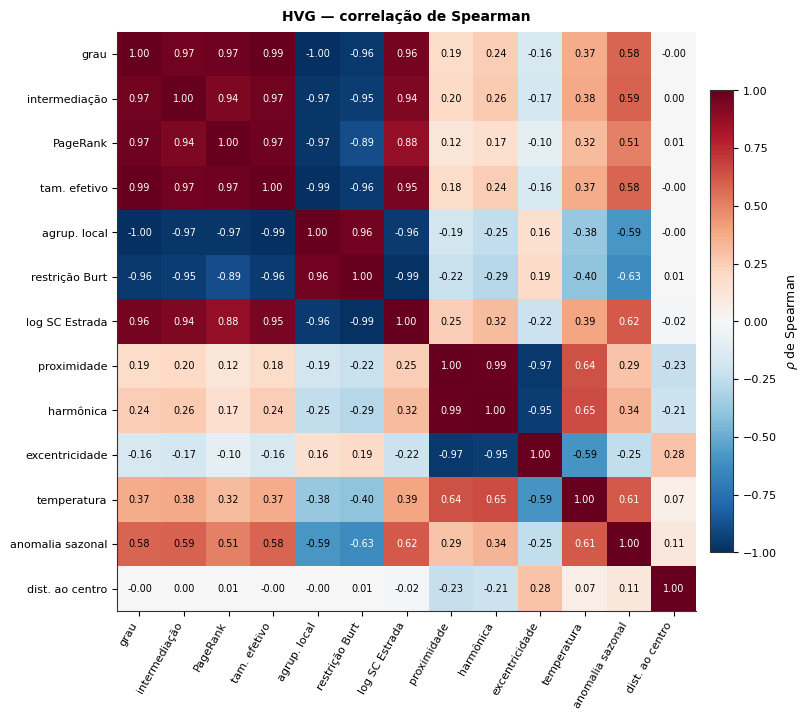

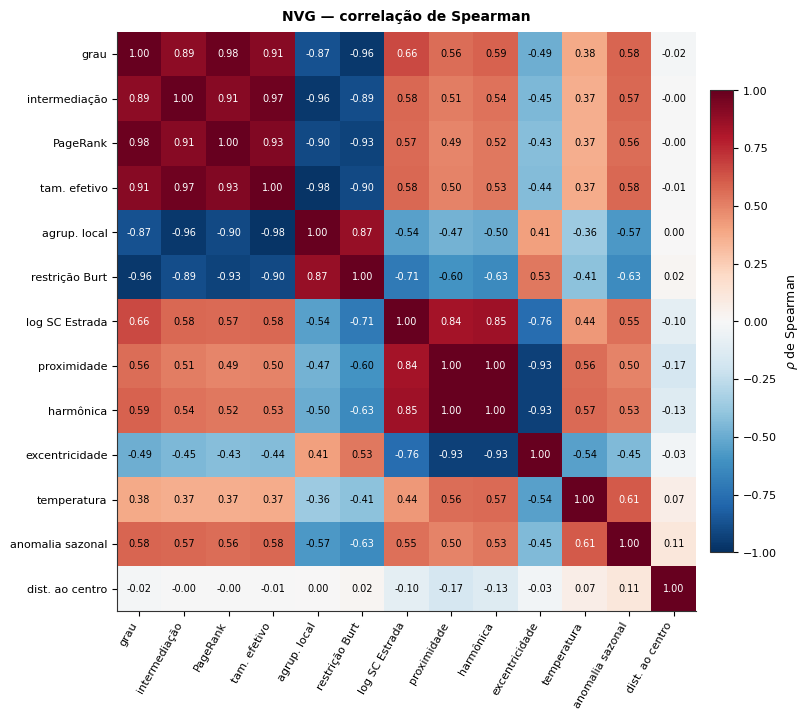

Correlação com a distância ao centro da série (efeito de borda):
HVG {'proximidade': -0.23, 'harmonica': -0.21, 'excentricidade': 0.28, 'grau': -0.0, 'intermediacao': 0.0}
NVG {'proximidade': -0.17, 'harmonica': -0.13, 'excentricidade': -0.03, 'grau': -0.02, 'intermediacao': -0.0}


In [ ]:
ORDEM = [
    "grau", "intermediacao", "pagerank", "burt_tamanho_efetivo", "agrup_local", "burt_restricao",
    "estrada_log10", "proximidade", "harmonica", "excentricidade", "temp_max", "anomalia", "dist_centro",
]
ROTULOS = {
    "grau": "grau", "intermediacao": "intermediação", "pagerank": "PageRank", "burt_tamanho_efetivo": "tam. efetivo",
    "agrup_local": "agrup. local", "burt_restricao": "restrição Burt", "estrada_log10": "log SC Estrada",
    "proximidade": "proximidade", "harmonica": "harmônica", "excentricidade": "excentricidade",
    "temp_max": "temperatura", "anomalia": "anomalia sazonal", "dist_centro": "dist. ao centro",
}

matrizes_spearman = {}
for nome in ("HVG", "NVG"):
    fig, ax = plt.subplots(figsize=(9, 8))
    df = cent[nome].copy()
    df["dist_centro"] = np.abs(np.arange(N) - (N - 1) / 2)
    S = df[ORDEM].corr(method="spearman")
    matrizes_spearman[nome] = S
    S.to_csv(PROCESSED_DIR / f"spearman_{nome.lower()}.csv")

    im = ax.imshow(S.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(ORDEM)))
    ax.set_yticks(range(len(ORDEM)))
    ax.set_xticklabels([ROTULOS[c] for c in ORDEM], rotation=60, ha="right", fontsize=8)
    ax.set_yticklabels([ROTULOS[c] for c in ORDEM], fontsize=8)
    for i in range(len(ORDEM)):
        for j in range(len(ORDEM)):
            ax.text(j, i, f"{S.values[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(S.values[i, j]) > 0.6 else "black")
    ax.set_title(f"{nome} — correlação de Spearman", pad=8)

    fig.colorbar(im, ax=ax, shrink=0.75, pad=0.02, label=r"$\rho$ de Spearman")
    salvar_fig(fig, f"parte3_spearman_centralidades_{nome.lower()}")

print("Correlação com a distância ao centro da série (efeito de borda):")
for nome in ("HVG", "NVG"):
    S = matrizes_spearman[nome]
    print(nome, S.loc["dist_centro", ["proximidade", "harmonica", "excentricidade", "grau", "intermediacao"]].round(2).to_dict())

## 17 · Distribuições das centralidades

Distribuições complementares empíricas (CCDF) em escala log-log para intermediação , PageRank e distribuição da centralidade harmônica.

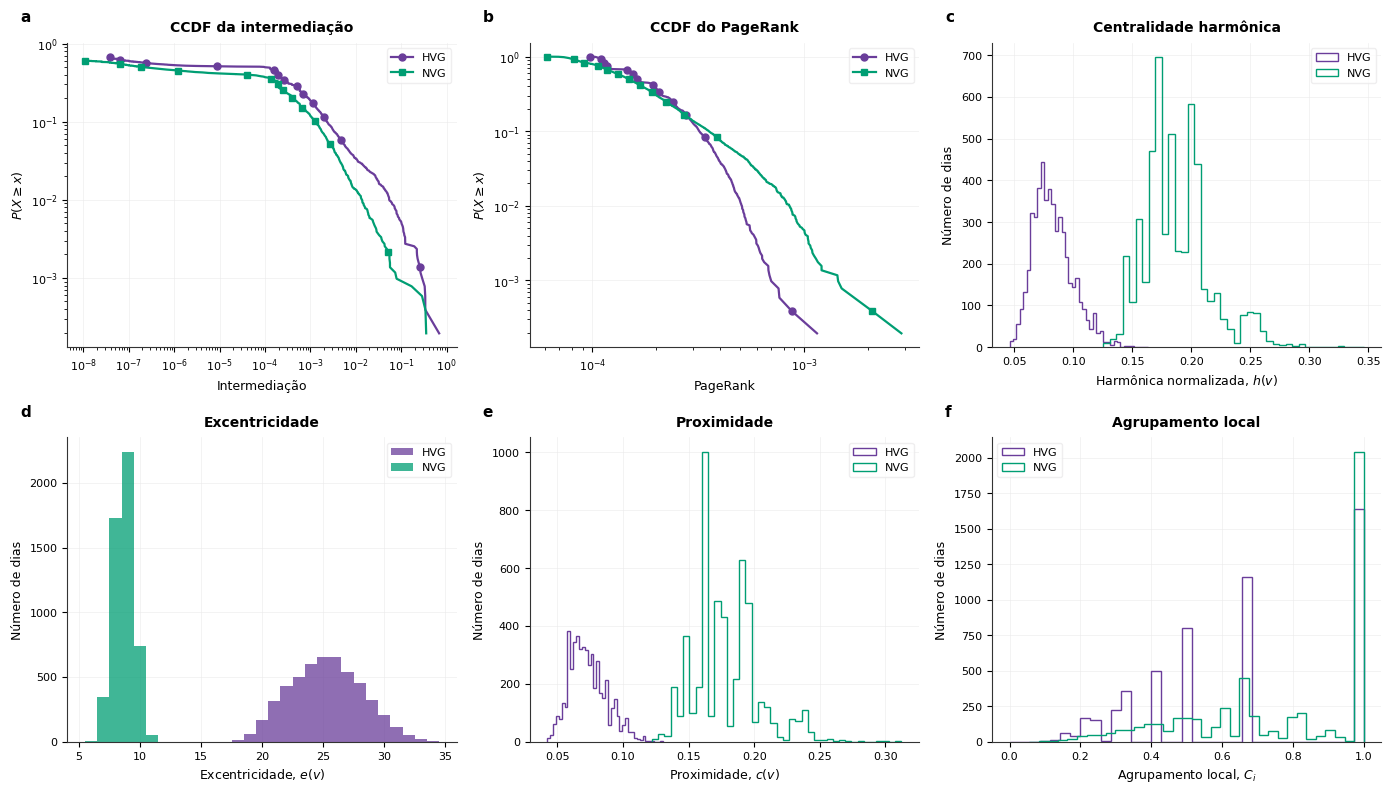

In [ ]:
def calcular_ccdf(valores):
    v = np.sort(valores[valores > 0])
    n = len(valores)
    p = np.arange(len(v), 0, -1) / n
    return v, p

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for ax in axes:
    estilizar_ax(ax)

for nome, cor in CORES_REDE.items():
    df = cent[nome]

    # a) CCDF Intermediação
    x, y = calcular_ccdf(df["intermediacao"].to_numpy())
    axes[0].loglog(x, y, "-", color=cor, lw=1.6, marker=MARCADOR_REDE[nome], markevery=max(1, len(x)//12), label=nome)

    # b) CCDF PageRank
    x, y = calcular_ccdf(df["pagerank"].to_numpy())
    axes[1].loglog(x, y, "-", color=cor, lw=1.6, marker=MARCADOR_REDE[nome], markevery=max(1, len(x)//12), label=nome)

    # c) Harmônica
    axes[2].hist(df["harmonica"], bins=40, histtype="step", lw=1.6, color=cor, label=nome)

    # d) Excentricidade
    ecc_min = min(cent["HVG"]["excentricidade"].min(), cent["NVG"]["excentricidade"].min())
    ecc_max = max(cent["HVG"]["excentricidade"].max(), cent["NVG"]["excentricidade"].max())
    bins_ecc = np.arange(ecc_min - 0.5, ecc_max + 1.5, 1)
    axes[3].hist(df["excentricidade"], bins=bins_ecc, alpha=0.75, color=cor, edgecolor="none", label=nome)

    # e) Proximidade
    axes[4].hist(df["proximidade"], bins=40, histtype="step", lw=1.6, color=cor, label=nome)

    # f) Agrupamento Local
    axes[5].hist(df["agrup_local"], bins=35, histtype="step", lw=1.6, color=cor, label=nome)

axes[0].set_title("CCDF da intermediação", pad=8)
axes[0].set_xlabel("Intermediação")
axes[0].set_ylabel(r"$P(X \geq x)$")
axes[0].legend(fontsize=8)

axes[1].set_title("CCDF do PageRank", pad=8)
axes[1].set_xlabel("PageRank")
axes[1].set_ylabel(r"$P(X \geq x)$")
axes[1].legend(fontsize=8)

axes[2].set_title("Centralidade harmônica", pad=8)
axes[2].set_xlabel("Harmônica normalizada, $h(v)$")
axes[2].set_ylabel("Número de dias")
axes[2].legend(fontsize=8)

axes[3].set_title("Excentricidade", pad=8)
axes[3].set_xlabel("Excentricidade, $e(v)$")
axes[3].set_ylabel("Número de dias")
axes[3].legend(fontsize=8)

axes[4].set_title("Proximidade", pad=8)
axes[4].set_xlabel("Proximidade, $c(v)$")
axes[4].set_ylabel("Número de dias")
axes[4].legend(fontsize=8)

axes[5].set_title("Agrupamento local", pad=8)
axes[5].set_xlabel("Agrupamento local, $C_i$")
axes[5].set_ylabel("Número de dias")
axes[5].legend(fontsize=8)

for i, ax in enumerate(axes):
    rotular_painel(ax, chr(97 + i))

plt.tight_layout()
salvar_fig(fig, "parte3_distribuicoes_centralidades")

## 18 · Quais são os dias mais centrais?

Dez dias mais centrais por intermediação e por proximidade, com temperatura e indicação de onda de calor (CTX90pct e EHF).

In [ ]:
flags_onda = {"ctx90": flag_ctx, "ehf": flag_ehf}


def tabela_top(nome, coluna, n_top=10):
    df = cent[nome]
    topo = df.sort_values(coluna, ascending=False).head(n_top)
    return pd.DataFrame({
        "posição": range(1, n_top + 1),
        "data": topo["data"].dt.date.to_numpy(),
        "temp_max": topo["temp_max"].round(1).to_numpy(),
        coluna: topo[coluna].round(4).to_numpy(),
        "CTX90pct": flag_ctx[topo.index.to_numpy()],
        "EHF": flag_ehf[topo.index.to_numpy()],
    })


linhas_top = []
for nome in ("HVG", "NVG"):
    for coluna in ("intermediacao", "proximidade", "pagerank"):
        t = tabela_top(nome, coluna)
        print(f"\n--- {nome} — top 10 por {coluna} ---")
        print(t.to_string(index=False))
        linhas_top.append(t.assign(rede=nome, metrica=coluna).rename(columns={coluna: "valor"}))
pd.concat(linhas_top).to_csv(PROCESSED_DIR / "parte3_top_dias.csv", index=False)


--- HVG — top 10 por intermediacao ---
 posição       data  temp_max  intermediacao  CTX90pct   EHF
       1 2013-11-26      32.2         0.6858     False False
       2 2019-03-22      32.3         0.3401      True False
       3 2013-04-07      31.8         0.3390      True False
       4 2015-02-06      31.2         0.3295     False False
       5 2013-02-10      31.2         0.2922     False False
       6 2010-03-15      32.2         0.2663      True  True
       7 2008-03-12      32.0         0.2653      True False
       8 2017-04-01      31.2         0.2430     False  True
       9 2011-04-02      31.0         0.2303     False False
      10 2020-03-22      32.5         0.2238      True False

--- HVG — top 10 por proximidade ---
 posição       data  temp_max  proximidade  CTX90pct   EHF
       1 2013-11-26      32.2       0.1304     False False
       2 2019-03-22      32.3       0.1236      True False
       3 2015-02-06      31.2       0.1232     False False
       4 2010-0

## 19 · Centralidade vs. Ondas de Calor

- **AUC:** Capacidade de discriminar dias de onda de calor (0,5 = nulo). p-valor via deslocamentos circulares.
- **Referência:** Temperatura e anomalia sazonal.
- **AUC Condicional:** Avalia se, a uma mesma anomalia de temperatura, os dias de onda são mais ou menos centrais.

In [ ]:
METRICAS_AUC = ["grau", "intermediacao", "pagerank", "proximidade", "harmonica", "excentricidade",
                "burt_restricao", "agrup_local", "estrada_log10", "k_nucleo"]
INVERTIDAS = {"excentricidade", "burt_restricao"}   # menor valor = mais central


def auc_rank(escore, flag):
    r = rankdata(escore)
    n1 = flag.sum()
    n0 = len(flag) - n1
    return (r[flag].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


rng_auc = np.random.default_rng(42)
deslocamentos = rng_auc.integers(365, N - 365, 2000)
decis = pd.qcut(anomalias, 10, labels=False)


def auc_condicional(escore, flag):
    num = den = 0.0
    for b in range(10):
        m = decis == b
        f = flag[m]
        if f.sum() < 5 or (~f).sum() < 5:
            continue
        w = f.sum() * (~f).sum()
        num += auc_rank(escore[m], f) * w
        den += w
    return num / den


def avaliar(escore, flag):
    r = rankdata(escore)
    n1 = flag.sum()
    a = auc_rank(escore, flag)
    nulo = np.array([(r[np.roll(flag, s)].sum() - n1 * (n1 + 1) / 2) / (n1 * (N - n1)) for s in deslocamentos])
    p = (np.abs(nulo - 0.5) >= abs(a - 0.5)).mean()
    return a, max(p, 1 / len(deslocamentos))


linhas = []
for evento, flag in (("CTX90pct", flag_ctx), ("EHF", flag_ehf)):
    for nome in ("HVG", "NVG"):
        df = cent[nome]
        for metrica in METRICAS_AUC:
            v = df[metrica].to_numpy()
            if np.unique(v).size < 2:
                continue       # HVG: k-núcleo é constante
            s = -v if metrica in INVERTIDAS else v
            a, p = avaliar(s, flag)
            linhas.append({"rede": nome, "metrica": metrica, "evento": evento, "AUC": a, "p": p,
                           "AUC condicional": auc_condicional(s, flag)})
    for ref, v in (("temperatura", serie_temp_max_bruta), ("anomalia sazonal", anomalias)):
        a, p = avaliar(v, flag)
        linhas.append({"rede": "referência", "metrica": ref, "evento": evento, "AUC": a, "p": p, "AUC condicional": np.nan})

tabela_auc = pd.DataFrame(linhas)
tabela_auc.to_csv(PROCESSED_DIR / "parte3_auc_ondas.csv", index=False)
print(f"\n{'='*90}\n  AUC (p mínimo = {1 / len(deslocamentos):.4f}) e AUC condicional à anomalia\n{'='*90}")
print(
    tabela_auc.pivot_table(index=["rede", "metrica"], columns="evento", values=["AUC", "AUC condicional", "p"])
    .round(3)
    .to_string()
)


  AUC (p mínimo = 0.0005) e AUC condicional à anomalia
                                 AUC        AUC condicional               p       
evento                      CTX90pct    EHF        CTX90pct    EHF CTX90pct    EHF
rede       metrica                                                                
HVG        agrup_local         0.383  0.477           0.704  0.607    0.000  0.000
           burt_restricao      0.638  0.530           0.292  0.386    0.000  0.000
           estrada_log10       0.628  0.529           0.289  0.388    0.000  0.000
           excentricidade      0.684  0.601           0.566  0.550    0.016  0.509
           grau                0.605  0.520           0.283  0.390    0.000  0.000
           harmonica           0.734  0.682           0.573  0.622    0.000  0.158
           intermediacao       0.639  0.531           0.333  0.400    0.000  0.000
           pagerank            0.576  0.502           0.283  0.386    0.000  0.772
           proximidade         

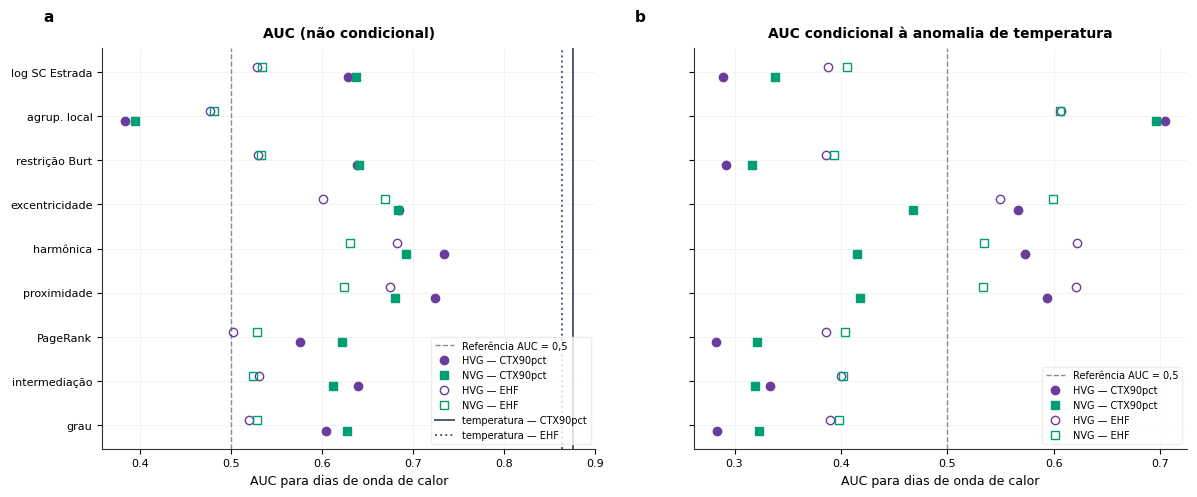

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
ordem_met = [m for m in METRICAS_AUC if m != "k_nucleo"]
ypos = np.arange(len(ordem_met))
marcadores = {"HVG": ("o", COR_HVG), "NVG": ("s", COR_NVG)}

for ax, (titulo, coluna) in zip(axes, (("AUC (não condicional)", "AUC"), ("AUC condicional à anomalia de temperatura", "AUC condicional"))):
    estilizar_ax(ax)
    ax.axvline(0.5, color=COR_NULO, lw=1, ls="--", label="Referência AUC = 0,5")
    for evento, preench in (("CTX90pct", True), ("EHF", False)):
        for nome, (mk, cor) in marcadores.items():
            sub = tabela_auc[(tabela_auc["rede"] == nome) & (tabela_auc["evento"] == evento)].set_index("metrica")
            xs = [sub.loc[m, coluna] if m in sub.index else np.nan for m in ordem_met]
            ax.plot(xs, ypos + (0.12 if evento == "EHF" else -0.12), mk, color=cor, ms=6,
                    mfc=cor if preench else "none", label=f"{nome} — {evento}")
    if coluna == "AUC":
        for evento, ls in (("CTX90pct", "-"), ("EHF", ":")):
            ref = tabela_auc[(tabela_auc["rede"] == "referência") & (tabela_auc["evento"] == evento) & (tabela_auc["metrica"] == "temperatura")]["AUC"].iloc[0]
            ax.axvline(ref, color="#4F5D75", lw=1.4, ls=ls, label=f"temperatura — {evento}")
    ax.set_title(titulo, pad=8, fontweight="bold")
    rotular_painel(ax, "a" if coluna == "AUC" else "b")
    ax.set_xlabel("AUC para dias de onda de calor")
    ax.set_yticks(ypos)
    ax.set_yticklabels([ROTULOS.get(m, m) for m in ordem_met])
    ax.invert_yaxis()
    ax.legend(fontsize=7, loc="lower right")

salvar_fig(fig, "parte3_auc_ondas")

## 20 · Núcleos e centralidade ao longo da série

Posição dos dias de maior centralidade na série temporal: cor pela centralidade harmônica (HVG e NVG) e destaque do núcleo máximo do NVG.

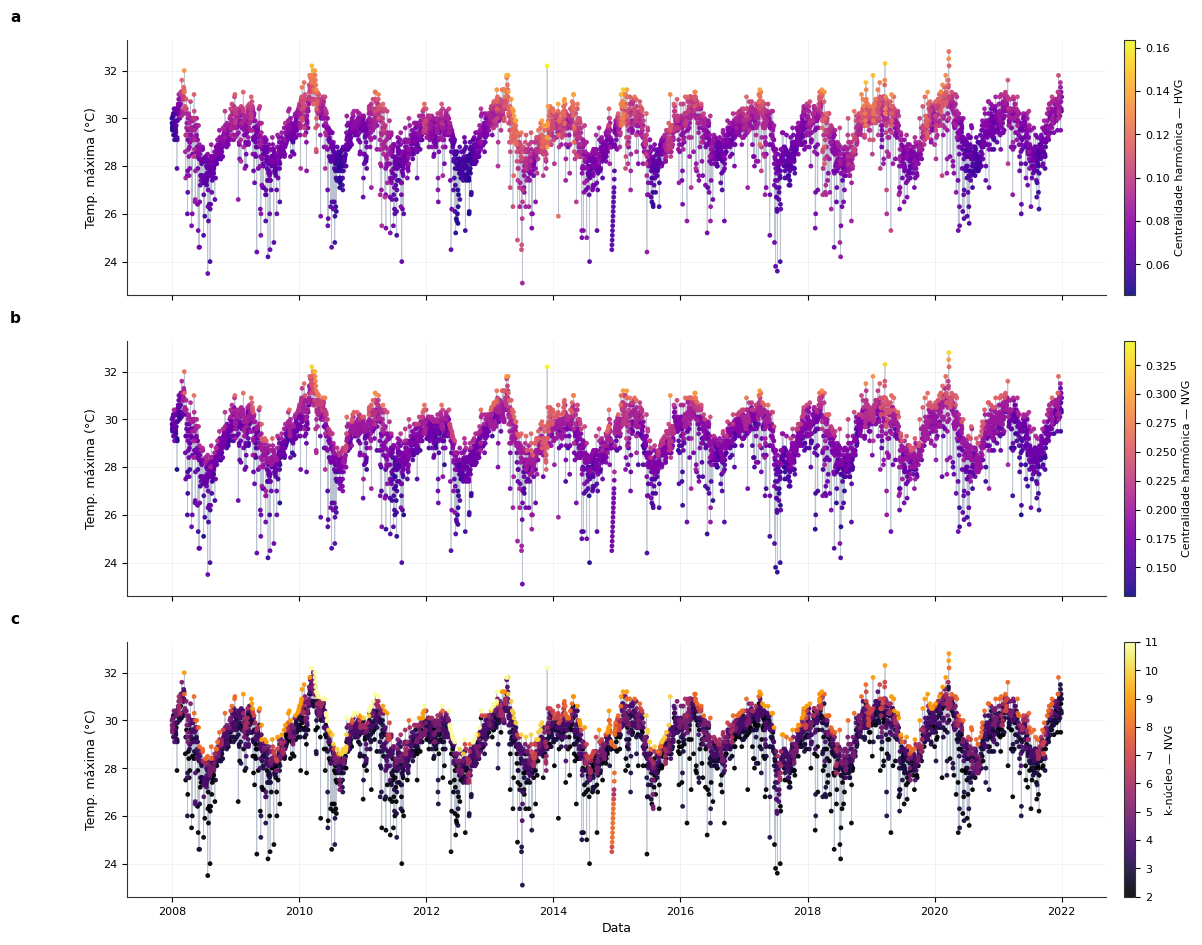

Núcleo máximo do NVG (k=11): 51 dias; temperatura média 30.44 °C (série: 29.18 °C); em onda CTX90pct: 13.7% (base 3.9%); EHF: 9.8% (base 8.1%).


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

df_recorte = pd.read_parquet(PROCESSED_DIR / "fortaleza_diario.parquet")
df_recorte["data"] = pd.to_datetime(df_recorte["data"])
df_recorte = df_recorte[(df_recorte['data'] >= '2008-01-01') & (df_recorte['data'] <= '2021-12-31')].reset_index(drop=True)

datas_plot = df_recorte["data"].to_numpy()
temps_plot = serie_temp_max_bruta

fig, axes = plt.subplots(3, 1, figsize=(13, 9.5), sharex=True)

paineis = [
    (axes[0], cent["HVG"]["harmonica"].to_numpy(), "Centralidade harmônica — HVG", "plasma", "a"),
    (axes[1], cent["NVG"]["harmonica"].to_numpy(), "Centralidade harmônica — NVG", "plasma", "b"),
    (axes[2], cent["NVG"]["k_nucleo"].to_numpy(), "k-núcleo — NVG", "inferno", "c"),
]

for ax, valores_cor, rotulo_cbar, cmap_nome, letra in paineis:
    estilizar_ax(ax)
    ax.plot(datas_plot, temps_plot, color=COR_TEMP, lw=0.5, alpha=0.6, zorder=1)

    # Ordena para desenhar os pontos mais centrais por cima
    ordem = np.argsort(valores_cor)
    sc = ax.scatter(
        datas_plot[ordem],
        temps_plot[ordem],
        c=valores_cor[ordem],
        cmap=cmap_nome,
        s=6,
        alpha=0.9,
        zorder=2,
    )
    ax.set_ylabel("Temp. máxima (°C)")
    rotular_painel(ax, letra)

    cb = fig.colorbar(sc, ax=ax, pad=0.015, aspect=22)
    cb.set_label(rotulo_cbar, fontsize=8, color=TEXTO)
    cb.ax.tick_params(colors=TEXTO, labelsize=8)

axes[2].set_xlabel("Data")
plt.tight_layout()
salvar_fig(fig, "parte3_serie_harmonica_kcore")

nucleo = cent["NVG"]["k_nucleo"] == cent["NVG"]["k_nucleo"].max()
print(
    f"Núcleo máximo do NVG (k={int(cent['NVG']['k_nucleo'].max())}): {int(nucleo.sum())} dias; "
    f"temperatura média {cent['NVG'].loc[nucleo, 'temp_max'].mean():.2f} °C "
    f"(série: {serie_temp_max_bruta.mean():.2f} °C); em onda CTX90pct: {flag_ctx[nucleo.to_numpy()].mean():.1%} "
    f"(base {flag_ctx.mean():.1%}); EHF: {flag_ehf[nucleo.to_numpy()].mean():.1%} (base {flag_ehf.mean():.1%})."
)

## 21 · Síntese da Parte III

- **Famílias de Centralidade:** Locais (grau, PageRank, etc.) vs. Geométricas (proximidade, excentricidade).
- **Efeito de Borda:** Geométricas sofrem distorção de borda no HVG; o NVG é mais robusto.
- **K-núcleos:** Núcleos densos no NVG contêm dias quentes, mas abrigam poucas ondas de calor de fato.
- **Assortatividade:** A topologia captura a forte autocorrelação temporal da temperatura.
- **Centralidade vs. Ondas:** Nenhuma centralidade supera a própria temperatura como detectora. Condicionando à temperatura, dias de onda são *menos* centrais (devido ao efeito de bloqueio topológico na visibilidade).

## 22 · Complementos e Robustez

1. **Alcance Temporal:** Distância média e máxima (em dias) da visibilidade.
2. **Assortatividade:** Validação contra redes reconfiguradas (mesmo grau).
3. **Desempate:** Correlação de Spearman entre redes com e sem empates.
4. **Interpolação:** Verificação de hubs após a remoção de dias imputados.
5. **Informação Incremental (Regressão):** Avaliação preditiva das centralidades sobre os modelos-base (temperatura + anomalia).

In [ ]:
def alcance_temporal(G):
    u = np.array([a for a, b in G.edges()])
    v = np.array([b for a, b in G.edges()])
    dt = np.abs(u - v).astype(float)
    k = np.array([G.degree(i) for i in range(N)], dtype=float)
    soma = np.bincount(u, dt, N) + np.bincount(v, dt, N)
    mx = np.zeros(N)
    np.maximum.at(mx, u, dt)
    np.maximum.at(mx, v, dt)
    return soma / k, mx


for nome, G in (("HVG", G_hvg), ("NVG", G_nvg)):
    cent[nome]["alcance_medio_dias"], cent[nome]["alcance_max_dias"] = alcance_temporal(G)
    cent[nome].to_csv(PROCESSED_DIR / f"centralidades_{nome.lower()}.csv", index=False)

linhas = []
for nome in ("HVG", "NVG"):
    df = cent[nome]
    for evento, flag in (("CTX90pct", flag_ctx), ("EHF", flag_ehf)):
        for col in ("alcance_medio_dias", "alcance_max_dias"):
            a, p = avaliar(df[col].to_numpy(), flag)
            linhas.append({"rede": nome, "métrica": col, "evento": evento, "AUC": a, "p": p})
    print(f"\n{nome}: alcance máximo = {df['alcance_max_dias'].max():.0f} dias "
          f"({df['alcance_max_dias'].max() / 365.25:.1f} anos); mediana = {df['alcance_max_dias'].median():.0f} dias")
    print(f"  Spearman(alcance máx., grau) = {spearmanr(df['alcance_max_dias'], df['grau'])[0]:.2f}; "
          f"Spearman(alcance máx., temperatura) = {spearmanr(df['alcance_max_dias'], serie_temp_max)[0]:.2f}")
    topo = df.sort_values("alcance_max_dias", ascending=False).head(6)
    print("  Maiores alcances:", [(str(d.date()), int(a)) for d, a in zip(topo["data"], topo["alcance_max_dias"])])
alcance_auc = pd.DataFrame(linhas)
alcance_auc.to_csv(PROCESSED_DIR / "parte3_alcance_auc.csv", index=False)
print("\n", alcance_auc.pivot_table(index=["rede", "métrica"], columns="evento", values=["AUC", "p"]).round(3).to_string())


HVG: alcance máximo = 3294 dias (9.0 anos); mediana = 2 dias
  Spearman(alcance máx., grau) = 0.94; Spearman(alcance máx., temperatura) = 0.39
  Maiores alcances: [('2010-03-15', 3294), ('2019-03-22', 3294), ('2013-11-26', 1942), ('2019-01-12', 1873), ('2018-12-02', 1832), ('2015-02-06', 1395)]

NVG: alcance máximo = 3661 dias (10.0 anos); mediana = 4 dias
  Spearman(alcance máx., grau) = 0.94; Spearman(alcance máx., temperatura) = 0.38
  Maiores alcances: [('2010-03-15', 3661), ('2020-03-23', 3661), ('2020-03-22', 3660), ('2010-03-23', 3653), ('2010-04-02', 3643), ('2019-03-22', 3294)]

                              AUC               p     
evento                  CTX90pct    EHF CTX90pct  EHF
rede métrica                                         
HVG  alcance_max_dias      0.666  0.539      0.0  0.0
     alcance_medio_dias    0.663  0.538      0.0  0.0
NVG  alcance_max_dias      0.640  0.544      0.0  0.0
     alcance_medio_dias    0.645  0.544      0.0  0.0


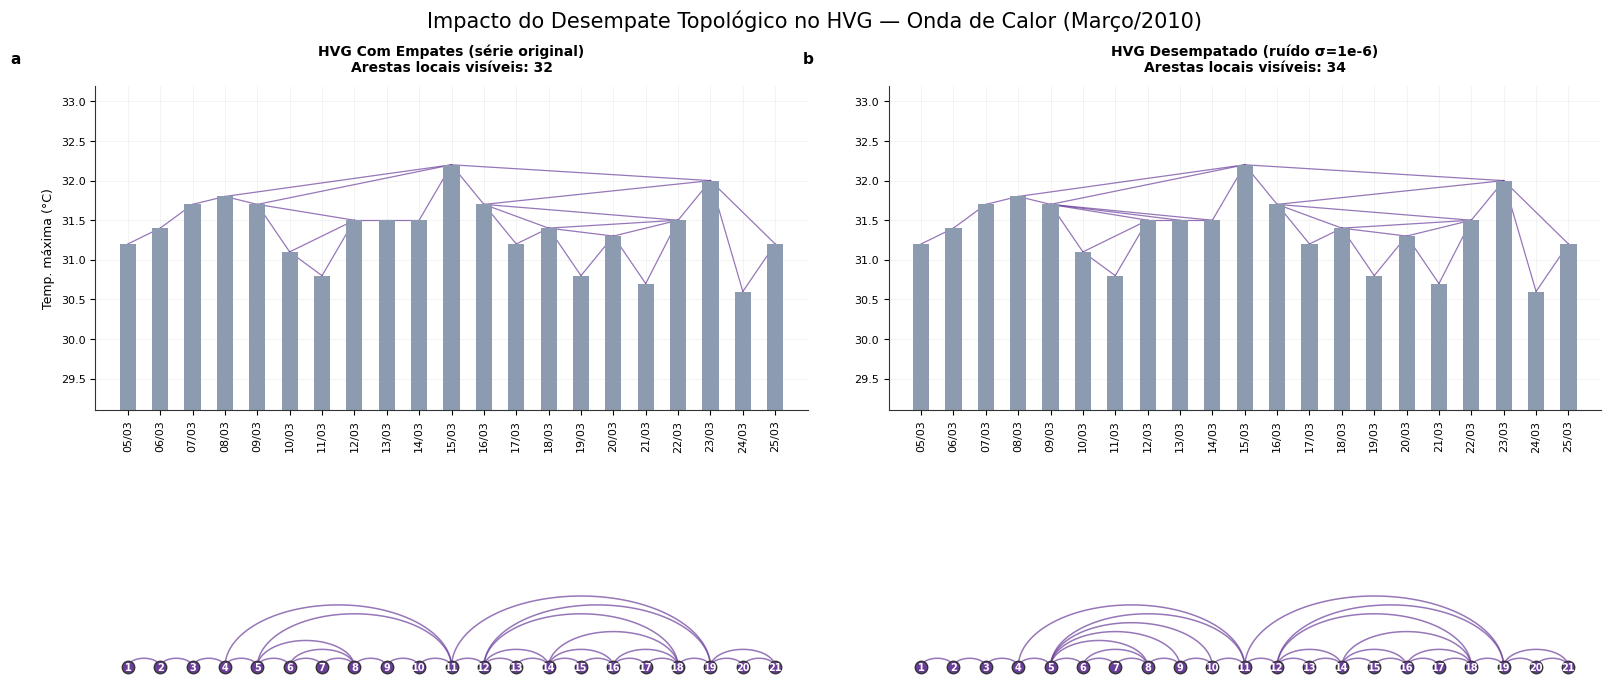

In [ ]:
centro_mar = idx_da_data("2010-03-15")
janela_mar = list(range(centro_mar - 10, centro_mar + 11))
n_nos = len(janela_mar)
x = np.arange(n_nos)
y = serie_temp_max_bruta[janela_mar]
datas_labels = [df_recorte["data"].iloc[i].strftime("%d/%m") for i in janela_mar]

fig, axes = plt.subplots(2, 2, figsize=(16, 7), height_ratios=[1.5, 1])
fig.suptitle("Impacto do Desempate Topológico no HVG — Onda de Calor (Março/2010)", fontsize=15, y=0.98)

# Mapeamento local para as arestas da sub-rede
mapa = {no_global: no_local for no_local, no_global in enumerate(janela_mar)}

for col_idx, (nome, G) in enumerate([
    ("HVG Com Empates (série original)", G_hvg_emp),
    ("HVG Desempatado (ruído σ=1e-6)", G_hvg)
]):
    ax_bar = axes[0, col_idx]
    ax_arc = axes[1, col_idx]

    estilizar_ax(ax_bar)

    sub = G.subgraph(janela_mar)
    arestas_locais = [(mapa[u], mapa[v]) for u, v in sub.edges()]

    base = y.min() - 1.5

    # Gráfico de barras (Série Temporal + Conexões)
    ax_bar.bar(x, y - base, bottom=base, width=0.5, color=COR_TEMP, zorder=2)
    for i, j in arestas_locais:
        ax_bar.plot([x[i], x[j]], [y[i], y[j]], color=COR_HVG, linewidth=0.9, alpha=0.7, zorder=1)

    ax_bar.set_xlim(-1, n_nos)
    ax_bar.set_ylim(base, y.max() + 1)
    if col_idx == 0:
        ax_bar.set_ylabel("Temp. máxima (°C)")
    ax_bar.set_xticks(x)
    ax_bar.set_xticklabels(datas_labels, rotation=90, fontsize=8)
    ax_bar.set_title(f"{nome}\nArestas locais visíveis: {len(arestas_locais)}", pad=10, fontweight="bold")

    ax_arc.scatter(x, np.zeros(n_nos), s=80, color=COR_HVG, edgecolor=BORDA, zorder=3)
    for posicao, lbl in enumerate(x):
        ax_arc.annotate(str(posicao + 1), (lbl, 0), ha="center", va="center", fontsize=7, fontweight="bold", zorder=4, color="white")

    for i, j in arestas_locais:
        centro = (x[i] + x[j]) / 2
        raio = abs(x[j] - x[i]) / 2
        theta = np.linspace(0, np.pi, 60)
        ax_arc.plot(centro + raio * np.cos(theta), raio * np.sin(theta) * 0.6,
                    color=COR_HVG, linewidth=1.1, alpha=0.7, zorder=2)

    ax_arc.set_xlim(-1, n_nos)
    ax_arc.set_ylim(-0.5, (n_nos / 2) * 0.6 + 0.5)
    ax_arc.axis("off")
    rotular_painel(ax_bar, "a" if col_idx == 0 else "b")

plt.tight_layout()
salvar_mostrar(fig, "comparacao_desempate_mar2010.svg")


## 23 · Validação com Blocos Contínuos (Sem Interpolação)

Para garantir que os resultados topológicos não sejam artefatos da interpolação linear, temos que isolar **blocos contínuos** na série histórica completa (2003–2023) onde não há dados ausentes.

In [ ]:
diario_raw = pd.read_parquet(PROCESSED_DIR / "fortaleza_diario.parquet")
diario_raw["data"] = pd.to_datetime(diario_raw["data"])
diario_raw = diario_raw.sort_values("data").reset_index(drop=True)

cal_completo = pd.date_range(diario_raw["data"].min(), diario_raw["data"].max(), freq="D")
diario_raw = diario_raw.set_index("data").reindex(cal_completo).rename_axis("data").reset_index()

diario_raw['is_missing'] = diario_raw['temp_max'].isna()
diario_raw['block_id'] = diario_raw['is_missing'].cumsum()
df_valid = diario_raw[~diario_raw['is_missing']].copy()

TAMANHO_MINIMO = 120
blocos_continuos = []

for block_id, group in df_valid.groupby('block_id'):
    if len(group) >= TAMANHO_MINIMO:
        blocos_continuos.append(group.copy())

print(f"Foram encontrados {len(blocos_continuos)} blocos contínuos com mais de {TAMANHO_MINIMO} dias.")

for i, bloco in enumerate(blocos_continuos):
    print(f"  Bloco {i+1}: {bloco['data'].min().date()} até {bloco['data'].max().date()} ({len(bloco)} dias)")

Foram encontrados 8 blocos contínuos com mais de 120 dias.
  Bloco 1: 2003-02-23 até 2003-07-14 (142 dias)
  Bloco 2: 2004-01-31 até 2004-06-01 (123 dias)
  Bloco 3: 2004-06-16 até 2004-11-26 (164 dias)
  Bloco 4: 2005-04-26 até 2005-11-22 (211 dias)
  Bloco 5: 2006-05-22 até 2007-03-17 (300 dias)
  Bloco 6: 2007-05-25 até 2014-12-03 (2750 dias)
  Bloco 7: 2014-12-18 até 2022-11-20 (2895 dias)
  Bloco 8: 2023-01-15 até 2023-06-22 (159 dias)


### 23.1 · Construção de Redes e Cálculo de Métricas por Bloco

Recalcular o $\langle k \rangle$ e o $\langle C \rangle$ no NVG e HVG desempatados, além da taxa-base de ondas de calor (CTX90pct e EHF) para cada bloco identificado.

In [ ]:
diario_ondas = pd.read_parquet(PROCESSED_DIR / "fortaleza_ondas_detectadas.parquet")
diario_ondas["data"] = pd.to_datetime(diario_ondas["data"])
mapa_ctx = dict(zip(diario_ondas["data"], diario_ondas["onda_ctx90"]))
mapa_ehf = dict(zip(diario_ondas["data"], diario_ondas["onda_ehf"]))

resultados_blocos = []
rng_des = np.random.default_rng(SEED_DESEMPATE)

for bloco in tqdm(blocos_continuos, desc="Analisando blocos"):
    datas = bloco['data'].values
    serie_temp = bloco['temp_max'].values.astype(np.float64)

    # Desempate com o mesmo critério
    serie_desempatada = serie_temp + rng_des.normal(0, SIGMA_DESEMPATE, len(serie_temp))

    # Centro de massa temporal do bloco
    data_inicio = pd.Timestamp(datas[0])
    data_fim = pd.Timestamp(datas[-1])
    data_media = data_inicio + (data_fim - data_inicio) / 2

    # Constrói redes
    hvg_bloco = HorizontalVG().build(serie_desempatada).as_networkx()
    nvg_bloco = NaturalVG().build(serie_desempatada).as_networkx()

    k_medio_hvg = np.mean([d for n, d in hvg_bloco.degree()])
    c_medio_hvg = nx.average_clustering(hvg_bloco)

    k_medio_nvg = np.mean([d for n, d in nvg_bloco.degree()])
    c_medio_nvg = nx.average_clustering(nvg_bloco)

    # Resgata as flags de onda para esses dias
    dias_ctx = np.array([mapa_ctx.get(pd.Timestamp(d), False) for d in datas])
    dias_ehf = np.array([mapa_ehf.get(pd.Timestamp(d), False) for d in datas])

    resultados_blocos.append({
        'data_inicio': data_inicio,
        'data_fim': data_fim,
        'data_media': data_media,
        'N_dias': len(bloco),
        'k_medio_hvg': k_medio_hvg,
        'c_medio_hvg': c_medio_hvg,
        'k_medio_nvg': k_medio_nvg,
        'c_medio_nvg': c_medio_nvg,
        'taxa_base_ctx': dias_ctx.mean(),
        'taxa_base_ehf': dias_ehf.mean()
    })

df_resultados_blocos = pd.DataFrame(resultados_blocos)
display(df_resultados_blocos.round(4).head())

,data_inicio,data_fim,data_media,N_dias,k_medio_hvg,c_medio_hvg,k_medio_nvg,c_medio_nvg,taxa_base_ctx,taxa_base_ehf
0,2003-02-23,2003-07-14,2003-05-04 12:00:00,142,3.7042,0.6244,5.6901,0.7447,0.00,0.0704
1,2004-01-31,2004-06-01,2004-04-01 00:00:00,123,3.7236,0.6157,5.6911,0.7367,0.00,0.0000
2,2004-06-16,2004-11-26,2004-09-05 12:00:00,164,3.7561,0.6411,5.2195,0.7282,0.00,0.0000
3,2005-04-26,2005-11-22,2005-08-09 00:00:00,211,3.9052,0.6308,6.7773,0.7453,0.00,0.0000
4,2006-05-22,2007-03-17,2006-10-18 12:00:00,300,3.8800,0.6433,6.3667,0.7463,0.01,0.0100


### 23.2 · Teste de Tendência de Mann-Kendall

Aplicando o teste nas séries temporais das métricas formadas pelos blocos.

In [ ]:
import pymannkendall as mk

df_resultados_blocos = df_resultados_blocos.sort_values('data_media')

print("\n=== TESTES DE MANN-KENDALL (Blocos Isolados) ===")
testes = {
    "K Médio (NVG)": df_resultados_blocos['k_medio_nvg'],
    "C Médio (NVG)": df_resultados_blocos['c_medio_nvg'],
    "K Médio (HVG)": df_resultados_blocos['k_medio_hvg'],
    "C Médio (HVG)": df_resultados_blocos['c_medio_hvg'],
    "Taxa de Ondas (CTX)": df_resultados_blocos['taxa_base_ctx'],
    "Taxa de Ondas (EHF)": df_resultados_blocos['taxa_base_ehf']
}

for nome, serie in testes.items():
    res = mk.original_test(serie)
    trend_str = {"no trend": "Sem tendência", "increasing": "Crescente", "decreasing": "Decrescente"}.get(res.trend, res.trend)
    print(f"{nome:20s}: {trend_str:13s} (p-value = {res.p:.4f}, Tau = {res.Tau:.3f})")


=== TESTES DE MANN-KENDALL (Blocos Isolados) ===
K Médio (NVG)       : Sem tendência (p-value = 0.5362, Tau = 0.214)
C Médio (NVG)       : Crescente     (p-value = 0.0187, Tau = 0.714)
K Médio (HVG)       : Sem tendência (p-value = 0.1078, Tau = 0.500)
C Médio (HVG)       : Sem tendência (p-value = 0.7105, Tau = 0.143)
Taxa de Ondas (CTX) : Crescente     (p-value = 0.0239, Tau = 0.643)
Taxa de Ondas (EHF) : Sem tendência (p-value = 0.2029, Tau = 0.393)


### 23.3 · Comparação Visual: Interpolado vs. Blocos Puros

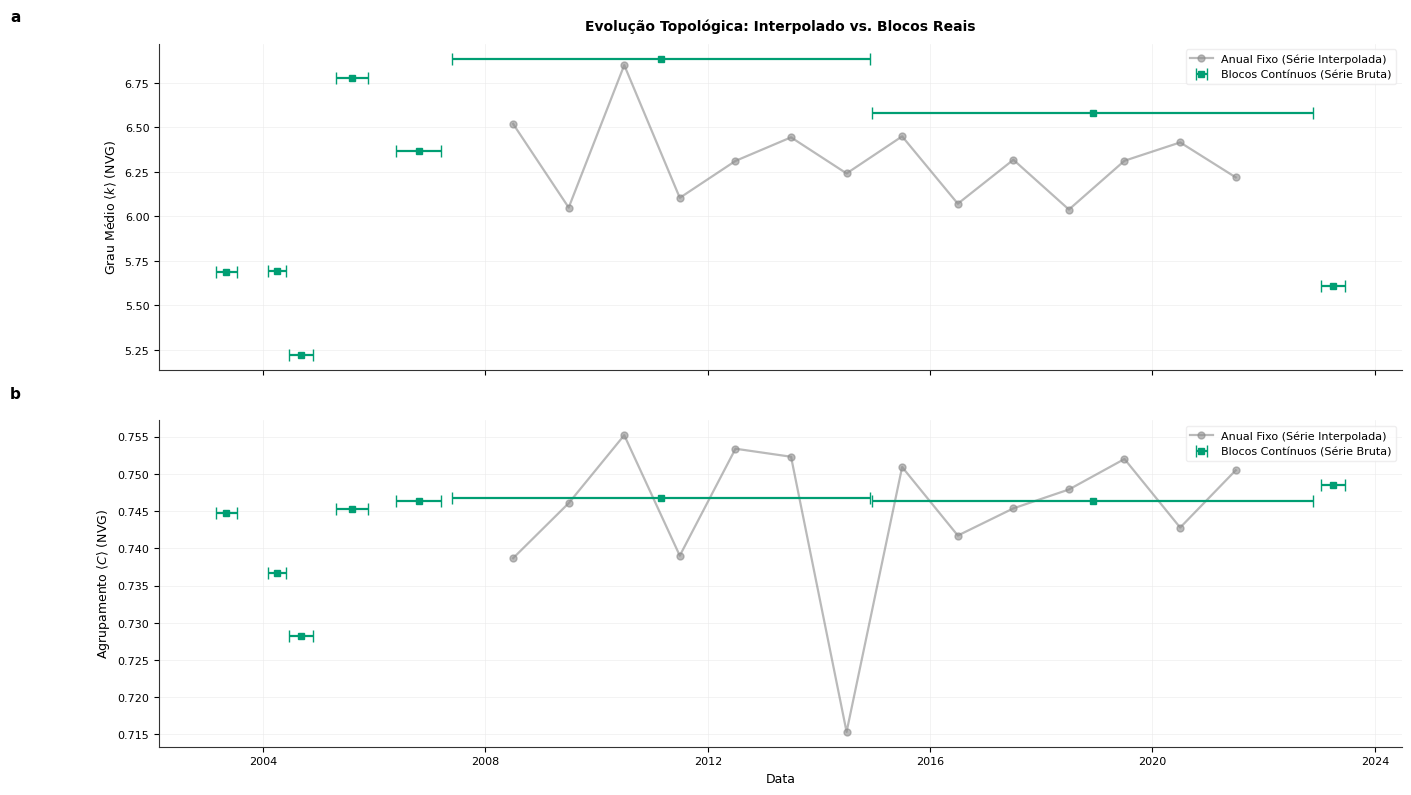

In [ ]:
resultados_anuais = []

for ano, grupo in df_recorte.groupby(df_recorte['data'].dt.year):
    if len(grupo) < 300:
        continue

    s_temp = grupo['temp_max'].values.astype(np.float64)
    s_des = s_temp + rng_des.normal(0, SIGMA_DESEMPATE, len(s_temp))

    nvg_a = NaturalVG().build(s_des).as_networkx()
    k_a = np.mean([d for n, d in nvg_a.degree()])
    c_a = nx.average_clustering(nvg_a)

    resultados_anuais.append({
        'ano': ano,
        'data_representativa': pd.Timestamp(year=ano, month=7, day=1),
        'k_medio_nvg': k_a,
        'c_medio_nvg': c_a
    })

df_anuais = pd.DataFrame(resultados_anuais)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
estilizar_ax(ax1)
estilizar_ax(ax2)

# Eixo 1: K médio NVG
ax1.plot(df_anuais['data_representativa'], df_anuais['k_medio_nvg'],
         '-o', color=COR_NULO, alpha=0.6, label='Anual Fixo (Série Interpolada)')

xerr_minus = df_resultados_blocos['data_media'] - df_resultados_blocos['data_inicio']
xerr_plus = df_resultados_blocos['data_fim'] - df_resultados_blocos['data_media']

ax1.errorbar(df_resultados_blocos['data_media'], df_resultados_blocos['k_medio_nvg'],
             xerr=[xerr_minus, xerr_plus], fmt='s', color=COR_NVG, capsize=4,
             label='Blocos Contínuos (Série Bruta)')

ax1.set_ylabel(r"Grau Médio $\langle k \rangle$ (NVG)")
ax1.set_title("Evolução Topológica: Interpolado vs. Blocos Reais", pad=10, fontweight="bold")
rotular_painel(ax1, "a")
rotular_painel(ax2, "b")
ax1.legend()

ax2.plot(df_anuais['data_representativa'], df_anuais['c_medio_nvg'],
         '-o', color=COR_NULO, alpha=0.6, label='Anual Fixo (Série Interpolada)')

ax2.errorbar(df_resultados_blocos['data_media'], df_resultados_blocos['c_medio_nvg'],
             xerr=[xerr_minus, xerr_plus], fmt='s', color=COR_NVG, capsize=4,
             label='Blocos Contínuos (Série Bruta)')

ax2.set_ylabel(r"Agrupamento $\langle C \rangle$ (NVG)")
ax2.set_xlabel("Data")
ax2.legend()

plt.tight_layout()
salvar_mostrar(fig, "comparacao_interpolado_vs_blocos.svg")

In [ ]:
rng_rw = np.random.default_rng(23)
N_REP_RW = 30
linhas = []
for nome, G in (("HVG", G_hvg), ("NVG", G_nvg)):
    nulo = []
    for _ in tqdm(range(N_REP_RW), desc=f"Reconfiguração {nome}"):
        g = G.copy()
        m = g.number_of_edges()
        nx.double_edge_swap(g, nswap=10 * m, max_tries=100 * m, seed=int(rng_rw.integers(1e9)))
        nulo.append(nx.degree_assortativity_coefficient(g))
    r_obs = nx.degree_assortativity_coefficient(G)
    linhas.append({"rede": nome, "r (grau)": r_obs, "reconfigurada média": np.mean(nulo),
                   "reconfigurada dp": np.std(nulo), "z": (r_obs - np.mean(nulo)) / np.std(nulo)})
assort_rw = pd.DataFrame(linhas)
assort_rw.to_csv(PROCESSED_DIR / "parte3_assortatividade_reconfigurada.csv", index=False)
print(assort_rw.round(4).to_string(index=False))

rede  r (grau)  reconfigurada média  reconfigurada dp       z
 HVG    0.1362               -0.003            0.0081 17.2187
 NVG    0.2139               -0.010            0.0086 26.0649


In [ ]:
cent_emp = {}
for nome, G in (("HVG", G_hvg_emp), ("NVG", G_nvg_emp)):
    cent_emp[nome] = calcular_centralidades(G)

linhas = []
for nome in ("HVG", "NVG"):
    for col in COLUNAS_CENT:
        a, b = cent[nome][col], cent_emp[nome][col]
        if a.nunique() > 1 and b.nunique() > 1:
            linhas.append({"rede": nome, "métrica": col, "Spearman (desempatada × com empates)": spearmanr(a, b)[0]})
rob_desempate = pd.DataFrame(linhas)
rob_desempate.to_csv(PROCESSED_DIR / "parte3_robustez_desempate.csv", index=False)
print(rob_desempate.pivot(index="métrica", columns="rede", values="Spearman (desempatada × com empates)").round(3).to_string())
print("\nK-núcleos com empates (HVG):", cent_emp["HVG"]["k_nucleo"].astype(int).value_counts().to_dict(),
      "| NVG máx.:", int(cent_emp["NVG"]["k_nucleo"].max()))

rede                    HVG    NVG
métrica                           
agrup_local           0.752  0.987
burt_restricao        0.938  0.992
burt_tamanho_efetivo  0.960  0.984
estrada_log10         0.890  0.992
excentricidade        0.964  0.990
grau                  0.961  0.993
harmonica             0.955  0.989
intermediacao         0.952  0.983
k_nucleo                NaN  0.972
pagerank              0.966  0.994
proximidade           0.953  0.989

K-núcleos com empates (HVG): {2: 5114} | NVG máx.: 11


In [ ]:
ok = ~mascara_interpolada
y_sem = serie_temp_max_bruta[ok] + np.random.default_rng(SEED_DESEMPATE).normal(0, SIGMA_DESEMPATE, ok.sum())
k_sem = np.bincount(np.array(arestas_hvg(y_sem)).ravel(), minlength=len(y_sem))
datas_sem = df_recorte["data"][ok].reset_index(drop=True)
i_c = int(np.where(df_recorte["data"] == "2014-12-02")[0][0])
i_s = int(np.where(datas_sem == "2014-12-02")[0][0])
print(f"Grau no HVG em 02/12/2014: {G_hvg.degree(i_c)} com interpolação | {k_sem[i_s]} sem os dias interpolados")
print("Maiores graus sem interpolação:", [(str(datas_sem[i].date()), int(k_sem[i])) for i in np.argsort(-k_sem)[:5]])
graus_c = np.array([G_hvg.degree(j) for j in range(N)])
print("Maiores graus com interpolação:", [(str(df_recorte["data"][i].date()), int(graus_c[i])) for i in np.argsort(-graus_c)[:5]])
print(df_recorte.set_index("data")["temp_max"]["2014-12-01":"2014-12-05"].round(2).to_dict())

Grau no HVG em 02/12/2014: 19 com interpolação | 6 sem os dias interpolados
Maiores graus sem interpolação: [('2013-11-26', 31), ('2016-06-21', 21), ('2019-11-22', 20), ('2019-01-12', 20), ('2016-01-29', 18)]
Maiores graus com interpolação: [('2013-11-26', 31), ('2019-11-22', 19), ('2014-12-02', 19), ('2016-06-21', 19), ('2019-01-12', 18)]
{Timestamp('2014-12-01 00:00:00'): 29.1, Timestamp('2014-12-02 00:00:00'): 29.0, Timestamp('2014-12-03 00:00:00'): 24.5, Timestamp('2014-12-04 00:00:00'): nan, Timestamp('2014-12-05 00:00:00'): nan}


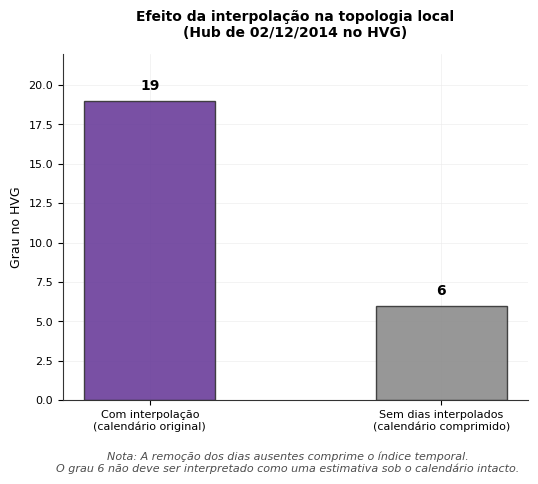

[OK] impacto_interpolacao_hub_02122014.svg gerado com sucesso em data/plots.


In [ ]:
grau_interpolado = G_hvg.degree(i_c)
grau_sem_interp = k_sem[i_s]

fig, ax = plt.subplots(figsize=(6, 4.5))
estilizar_ax(ax)

condicoes = ['Com interpolação\n(calendário original)', 'Sem dias interpolados\n(calendário comprimido)']
graus = [grau_interpolado, grau_sem_interp]

ax.bar(condicoes, graus, color=[COR_HVG, COR_NULO], width=0.45, edgecolor=BORDA, alpha=0.9)

for i, v in enumerate(graus):
    ax.text(i, v + 0.5, str(v), ha='center', va='bottom', fontweight='bold', color=TEXTO, fontsize=10)

ax.set_ylabel("Grau no HVG")
ax.set_title("Efeito da interpolação na topologia local\n(Hub de 02/12/2014 no HVG)", pad=12, fontweight="bold")
ax.set_ylim(0, max(graus) + 3)

fig.text(0.5, -0.05,
         "Nota: A remoção dos dias ausentes comprime o índice temporal.\nO grau 6 não deve ser interpretado como uma estimativa sob o calendário intacto.",
         ha="center", fontsize=8, color=COR_PICO, style="italic")

salvar_mostrar(fig, "impacto_interpolacao_hub_02122014.svg")
print(f"[OK] impacto_interpolacao_hub_02122014.svg gerado com sucesso em {PLOTS_DIR}.")

In [ ]:
anos = df_recorte["data"].dt.year.to_numpy()


def auc_cv(F, y):
    pred = np.zeros(N)
    for a in np.unique(anos):
        te = anos == a
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(F[~te], y[~te])
        pred[te] = m.predict_proba(F[te])[:, 1]
    return roc_auc_score(y, pred)


linhas = []
ref_F = np.column_stack([serie_temp_max, anomalias])
for evento, flag in (("CTX90pct", flag_ctx), ("EHF", flag_ehf)):
    linhas.append({"evento": evento, "modelo": "temperatura + anomalia (referência)", "AUC (CV por ano)": auc_cv(ref_F, flag)})
    for nome in ("HVG", "NVG"):
        cols = ["grau", "proximidade", "harmonica", "intermediacao", "pagerank", "agrup_local", "burt_restricao",
                "alcance_max_dias"] + (["k_nucleo"] if nome == "NVG" else [])
        Fc = np.log1p(cent[nome][cols].to_numpy())
        linhas.append({"evento": evento, "modelo": f"referência + centralidades {nome}", "AUC (CV por ano)": auc_cv(np.column_stack([ref_F, Fc]), flag)})
        linhas.append({"evento": evento, "modelo": f"somente centralidades {nome}", "AUC (CV por ano)": auc_cv(Fc, flag)})
auc_incremental = pd.DataFrame(linhas)
auc_incremental.to_csv(PROCESSED_DIR / "parte3_auc_incremental.csv", index=False)
print(auc_incremental.round(3).to_string(index=False))

  evento                              modelo  AUC (CV por ano)
CTX90pct temperatura + anomalia (referência)             0.919
CTX90pct      referência + centralidades HVG             0.926
CTX90pct           somente centralidades HVG             0.661
CTX90pct      referência + centralidades NVG             0.944
CTX90pct           somente centralidades NVG             0.590
     EHF temperatura + anomalia (referência)             0.834
     EHF      referência + centralidades HVG             0.876
     EHF           somente centralidades HVG             0.457
     EHF      referência + centralidades NVG             0.821
     EHF           somente centralidades NVG             0.481


## 24 · Visualização de Redes



Gerando gráfico para os dados completos mais recentes (2021)...


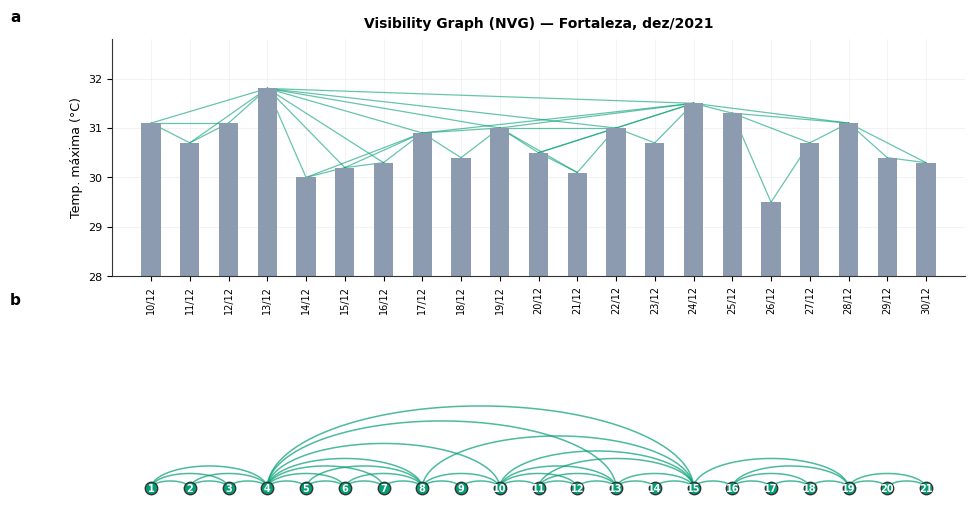

[OK] vg_exemplo_recente.svg — 43 arestas locais


In [ ]:
centro_recente = idx_da_data("2021-12-20")
janela_recente = list(range(centro_recente - 10, centro_recente + 11))


print("\nGerando gráfico para os dados completos mais recentes (2021)...")
plot_estilo_lacasa(
    janela_recente,
    "Visibility Graph (NVG) — Fortaleza, dez/2021",
    "vg_exemplo_recente.svg",
    G_nvg
)


## 25 · Topologia de Força (Kamada-Kawai)

A visualização a seguir plota apenas o subgrafo induzido pelas janelas temporais de interesse.

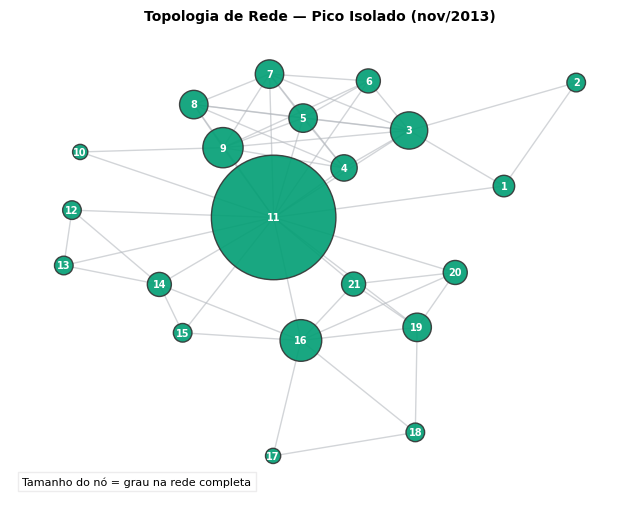

[OK] topologia_pico_isolado.svg gerado.


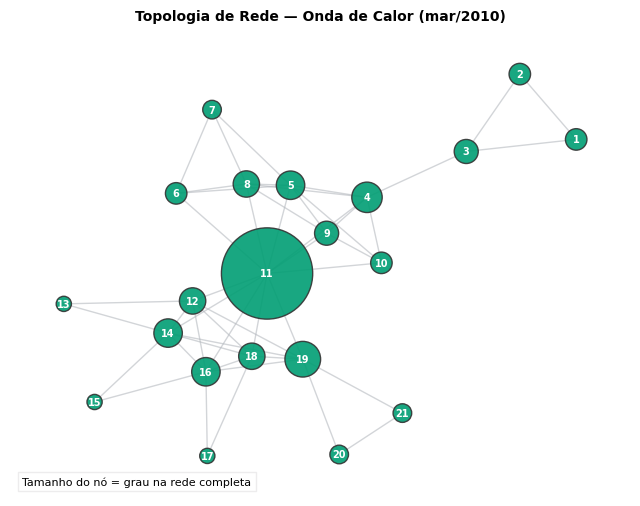

[OK] topologia_onda_calor.svg gerado.


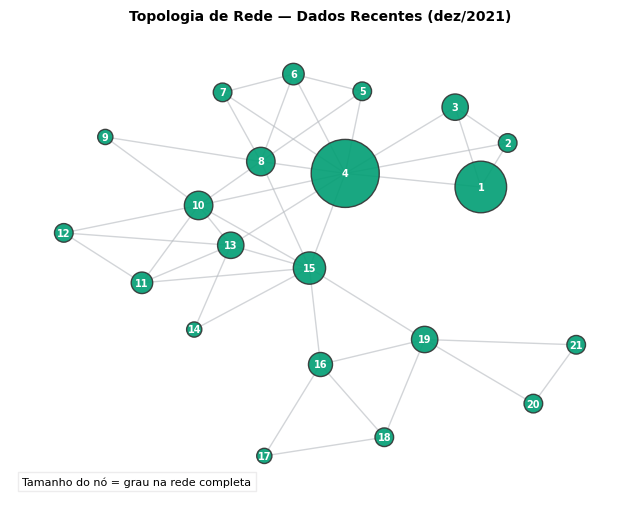

[OK] topologia_dados_recentes.svg gerado.


In [ ]:
def plot_topologia_forca(indices, titulo, arquivo_svg, G):
    """
    Gera o diagrama de nós e arestas usando o algoritmo de layout Kamada-Kawai.
    """
    indices_validos = [i for i in indices if i in G]
    if len(indices_validos) != len(indices):
        print(f"Aviso: {len(indices) - len(indices_validos)} índices ausentes no grafo foram ignorados.")

    subG = G.subgraph(indices_validos)

    fig, ax = plt.subplots(figsize=(8, 6), facecolor=FUNDO)
    ax.set_facecolor(CARTA)
    ax.axis("off")

    pos = nx.kamada_kawai_layout(subG)

    # 2. Grau Global vs Local

    graus_globais = dict(G.degree())
    tamanhos = [graus_globais[n] * 60 for n in subG.nodes()]

    # Desenhar arestas
    nx.draw_networkx_edges(
        subG, pos,
        edge_color=COR_ARESTA,
        alpha=0.6,
        ax=ax
    )

    # Desenhar nós
    nx.draw_networkx_nodes(
        subG, pos,
        node_color=COR_NVG,
        edgecolors=BORDA,
        node_size=tamanhos,
        alpha=0.9,
        ax=ax
    )

    # 3. Rótulos com contraste aprimorado
    mapa_rotulos = {no_global: str(posicao + 1) for posicao, no_global in enumerate(indices_validos)}
    nx.draw_networkx_labels(
        subG, pos,
        labels=mapa_rotulos,
        font_size=7,
        font_weight="bold",
        font_color="white",
        ax=ax
    )

    ax.set_title(titulo, pad=10, fontsize=10, fontweight="bold")
    ax.text(0.02, 0.02, "Tamanho do nó = grau na rede completa", transform=ax.transAxes,
            ha="left", va="bottom", fontsize=8, color=TEXTO,
            bbox={"facecolor": CARTA, "edgecolor": COR_GRID, "alpha": 0.9, "pad": 3})

    salvar_mostrar(fig, arquivo_svg)
    print(f"[OK] {arquivo_svg} gerado.")

plot_topologia_forca(
    janela1,
    "Topologia de Rede — Pico Isolado (nov/2013)",
    "topologia_pico_isolado.svg",
    G_nvg
)

plot_topologia_forca(
    janela2,
    "Topologia de Rede — Onda de Calor (mar/2010)",
    "topologia_onda_calor.svg",
    G_nvg
)

plot_topologia_forca(
    janela_recente,
    "Topologia de Rede — Dados Recentes (dez/2021)",
    "topologia_dados_recentes.svg",
    G_nvg
)

## 26 · Evolução Anual Consistente das Métricas

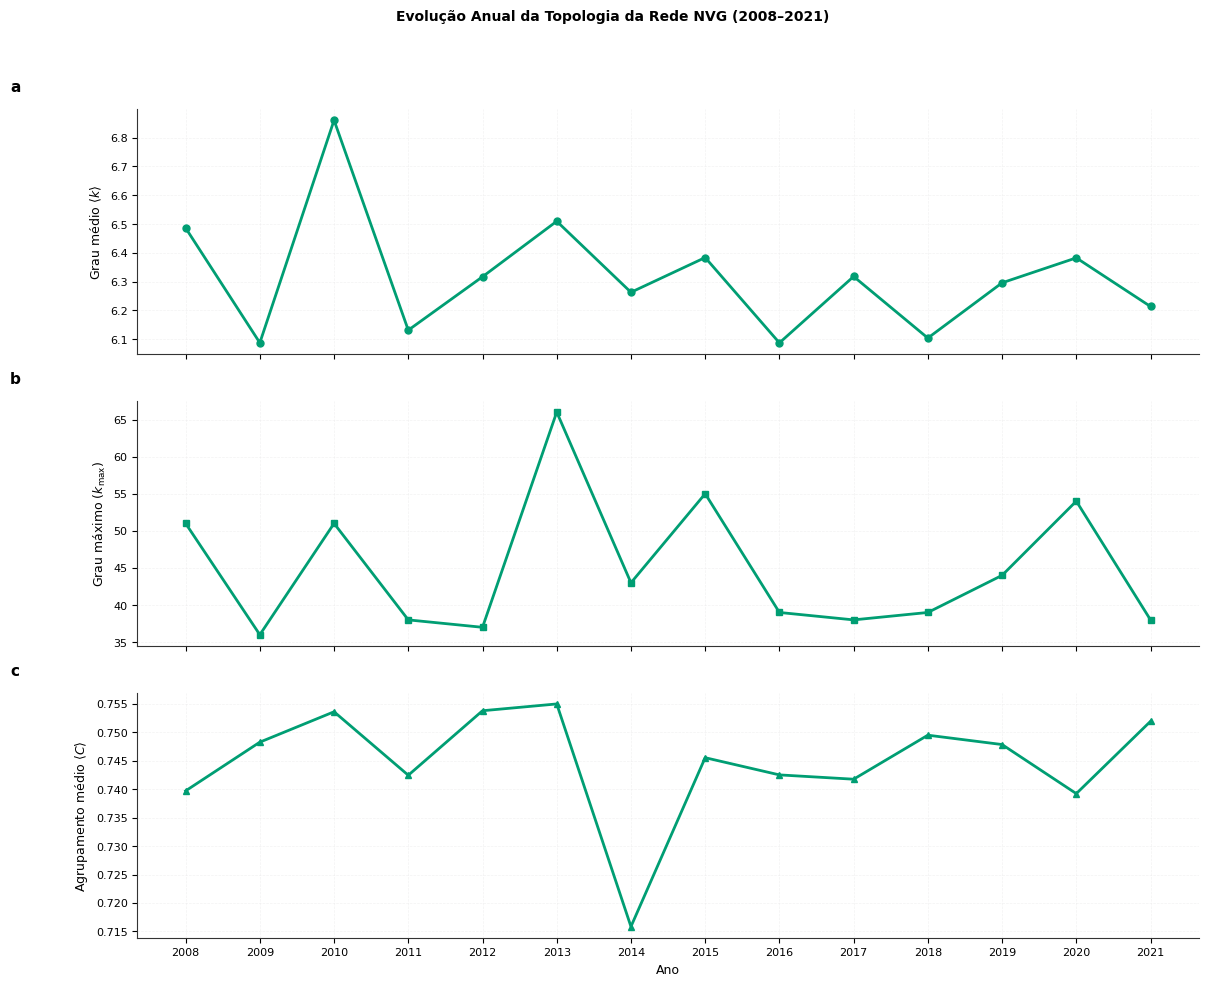

,Ano,Grau Médio <k>,Grau Máximo (Hub),Agrupamento Médio <C>,Densidade
0,2008,6.486,51,0.740,0.018
1,2009,6.088,36,0.748,0.017
2,2010,6.860,51,0.754,0.019
3,2011,6.132,38,0.742,0.017
4,2012,6.317,37,0.754,0.017
5,2013,6.510,66,0.755,0.018
6,2014,6.263,43,0.716,0.017
7,2015,6.384,55,0.746,0.018
8,2016,6.087,39,0.743,0.017
9,2017,6.318,38,0.742,0.017


In [ ]:
anos_unicos = df_recorte["data"].dt.year.unique()

metricas_por_ano = []
rng_des = np.random.default_rng(SEED_DESEMPATE)

for ano in anos_unicos:
    df_ano = df_recorte[df_recorte["data"].dt.year == ano]

    if len(df_ano) < 300:
        continue

    s_temp = df_ano["temp_max"].values.astype(np.float64)
    s_des = s_temp + rng_des.normal(0, SIGMA_DESEMPATE, len(s_temp))
    nvg_ano = NaturalVG().build(s_des).as_networkx()
    graus = [d for n, d in nvg_ano.degree()]

    metricas_por_ano.append({
        "Ano": ano,
        "Grau Médio <k>": np.mean(graus),
        "Grau Máximo (Hub)": np.max(graus),
        "Agrupamento Médio <C>": nx.average_clustering(nvg_ano),
        "Densidade": nx.density(nvg_ano)
    })

df_metricas_anuais = pd.DataFrame(metricas_por_ano)

# --- Plotando a evolução temporal ---
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
fig.suptitle("Evolução Anual da Topologia da Rede NVG (2008–2021)", fontsize=10, fontweight="bold", y=0.98)

# 1. Grau Médio
estilizar_ax(axes[0])
axes[0].plot(df_metricas_anuais["Ano"], df_metricas_anuais["Grau Médio <k>"], marker='o', color=COR_NVG, lw=2)
axes[0].set_ylabel(r"Grau médio $\langle k \rangle$")
rotular_painel(axes[0], "a")
axes[0].grid(True, linestyle="--", alpha=0.6)

estilizar_ax(axes[1])
axes[1].plot(df_metricas_anuais["Ano"], df_metricas_anuais["Grau Máximo (Hub)"], marker='s', color=COR_NVG, lw=2)
axes[1].set_ylabel(r"Grau máximo ($k_{\max}$)")
rotular_painel(axes[1], "b")
axes[1].grid(True, linestyle="--", alpha=0.6)

estilizar_ax(axes[2])
axes[2].plot(df_metricas_anuais["Ano"], df_metricas_anuais["Agrupamento Médio <C>"], marker='^', color=COR_NVG, lw=2)
axes[2].set_ylabel(r"Agrupamento médio $\langle C \rangle$")
rotular_painel(axes[2], "c")
axes[2].set_xlabel("Ano")
axes[2].set_xticks(df_metricas_anuais["Ano"])
axes[2].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout(rect=[0, 0, 1, 0.95])
salvar_mostrar(fig, "evolucao_anual_metricas_nvg.svg")

display(df_metricas_anuais.round(3))
